# Семинар 3. scRNA-seq: Аннотация


## 0. Подготовка окружения

Используйте окружение `sc_pbmc` из двух предыдущих занятий. При необходимости установите CellTypist отдельно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge -c bioconda "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph celltypist pandas numpy scipy matplotlib -y
```

Если в прошлые разы всё скачано то сейчас достаточно `mamba install -c conda-forge -c bioconda celltypist -y` или `pip install celltypist`

В ноутбуке указан `use_raw=False`: мы берём **лог-нормализованную** матрицу из `.X`, а не автоматически переключаемся на `.raw` (если он появится). Для последующего пересчёта HVG используем **сырые UMI-counts из `.layers['counts']`**.

In [1]:
from pathlib import Path
import sys
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=95, frameon=False, figsize=(6, 5))
np.random.seed(42)
sc.set_figure_params(
    figsize=(16, 8),
    dpi=100,
    frameon=False
)

### 0.1. Загрузка подготовленных результатов

**Предпочтительно:** `data/pbmc3k_after_clustering.h5ad`, который сохраняется в конце второго семинара. Для ноутбуков, запущенных в другой папке, исправьте значение `DATA_DIR` ниже.

Если файла нет, ячейка ниже восстановит **ту же последовательность операций**, что и во втором семинаре (QC → counts → HVG → normalize → log1p → PCA → граф → Leiden → UMAP). 

Это потребует наличия матрицы из первого занятия или заного скачать `sc.datasets.pbmc3k()`.

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

## Загрузка готовых результатов второго семинара

In [4]:

checkpoint = DATA_DIR / "pbmc3k_after_clustering.h5ad"

adata = sc.read_h5ad(checkpoint)

adata.var_names_make_unique()

print(adata)

display(
    adata.obs['leiden_1.0']
    .value_counts()
    .sort_index()
    .rename("n_cells")
    .to_frame()
)


AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden_0.2', 'leiden_1.0', 'leiden_2.0'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'leiden_0.2', 'leiden_0.2_colors', 'leiden_1.0', 'leiden_1.0_colors', 'leiden_2.0', 'leiden_2.0_colors', 'log1p', 'neighbors', 'pca', 'tsne', 'umap'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'


,n_cells
leiden_1.0,
0,553
1,536
2,378
3,347
4,341
5,157
6,156
7,107
8,30


## Обработка данных PBMC3k с нуля

Эта ячейка используется вместо первой, если готового файла нет

checkpoint = DATA_DIR / "pbmc3k_after_clustering.h5ad"
raw_dir = DATA_DIR / "filtered_gene_bc_matrices" / "hg19"


adata = sc.datasets.pbmc3k()
adata.var_names_make_unique()
    
# 2. Контроль качества
adata.var["mt"] = adata.var_names.str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    inplace=True
)

sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500)
    & (adata.obs["pct_counts_mt"] < 5)
].copy()

# 3. Сохранение исходных counts
adata.layers["counts"] = adata.X.copy()

# 4. Выбор высоковариабельных генов
sc.pp.highly_variable_genes(
    adata,
    layer="counts",
    flavor="seurat_v3",
    n_top_genes=2000
)

# 5. Нормализация и логарифмирование
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 6. PCA
sc.tl.pca(
    adata,
    n_comps=50,
    mask_var="highly_variable",
    random_state=42
)

# 7. Граф соседства
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    random_state=42
)

# 8. Кластеризация Leiden
for resolution in (0.2, 1.0, 2.0):
    sc.tl.leiden(
        adata,
        resolution=resolution,
        key_added=f"leiden_{resolution:.1f}",
        random_state=42
    )

# 9. UMAP
sc.tl.umap(
    adata,
    min_dist=0.3,
    random_state=42
)

# 10. Сохранение результатов
checkpoint.parent.mkdir(exist_ok=True, parents=True)
adata.write_h5ad(checkpoint, compression="gzip")

print(adata)

display(
    adata.obs[CLUSTER_KEY]
    .value_counts()
    .sort_index()
    .rename("n_cells")
    .to_frame()
)

![https://link.springer.com/article/10.15252/msb.20188746/figures/1](singlecell.png)

## Что было ДО 

# PCA 

![https://machinelearningcoban.com/2017/06/15/pca/](pcajpg.jpg)

# kNN 

![https://biocellgen-public.svi.edu.au/mig_2019_scrnaseq-workshop/clustering-and-cell-annotation.html](NearestNeighborNetworks.png)

# Graph connectivities

![https://discourse.scverse.org/t/methods-of-calculating-graphs/1870](dist.png)

# Modularity 

![](modularity.jpg)

# Louvain 

![](Louvain.jpg)

# Leiden

![https://www.nature.com/articles/s41598-019-41695-z](leiden.png)

# Переходим к Аннотации кластеров  

In [5]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden_0.2', 'leiden_1.0', 'leiden_2.0'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'leiden_0.2', 'leiden_0.2_colors', 'leiden_1.0', 'leiden_1.0_colors', 'leiden_2.0', 'leiden_2.0_colors', 'log1p', 'neighbors', 'pca', 'tsne', 'umap'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [6]:
adata.uns

{'hvg': {'flavor': 'seurat_v3'},
 'leiden_0.2': {'params': {'n_iterations': -1,
   'random_state': 0,
   'resolution': 0.2}},
 'leiden_0.2_colors': array(['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc'],
       dtype=object),
 'leiden_1.0': {'params': {'n_iterations': -1,
   'random_state': 0,
   'resolution': 1.0}},
 'leiden_1.0_colors': array(['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc', '#8c564b',
        '#e377c2', '#b5bd61', '#17becf', '#aec7e8', '#ffbb78'],
       dtype=object),
 'leiden_2.0': {'params': {'n_iterations': -1,
   'random_state': 0,
   'resolution': 2.0}},
 'leiden_2.0_colors': array(['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc', '#8c564b',
        '#e377c2', '#b5bd61', '#17becf', '#aec7e8', '#ffbb78', '#98df8a',
        '#ff9896', '#c5b0d5', '#c49c94', '#f7b6d2', '#dbdb8d'],
       dtype=object),
 'log1p': {},
 'neighbors': {'connectivities_key': 'connectivities',
  'distances_key': 'distances',
  'params': {'method': 'umap',
   'metric': 

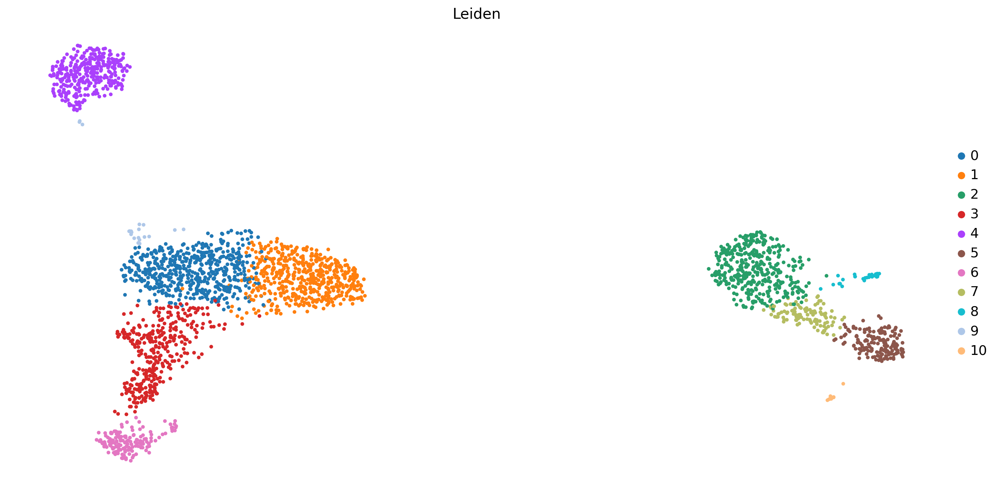

In [7]:
sc.pl.umap(adata, color='leiden_1.0',  size=50,
           title="Leiden")

# Очевидная идея - посмотреть на саммые экспрессируемые гены каждого кластера и попарно сравнить: кластер - кластер, кластер - все остальные клетки 

---
## 1. Что значит маркер кластера?

Пусть $x_{cg}$ — лог-нормализованная экспрессия гена $g$ в клетке $c$.

Для каждого кластера $A$ и гена $g$ сравниваем две группы:

- $A$: клетки данного кластера;
- $B$: все остальные клетки (`reference='rest'`) или клетки заранее выбранного второго кластера.

**Нулевая гипотеза рангового теста** — распределения экспрессии в группах одинаковы:

$$H_0:\ F_{g,A}(x)=F_{g,B}(x).$$

Альтернативная гипотеза (в реализации двустороннего теста) — распределения различаются. Часто нас интересуют гены с **положительным эффектом** и экспрессией у значительной доли клеток внутри кластера.

---
### 1.1. Wilcoxon rank-sum

**Критерий Уилкоксона для независимых выборок** не требует нормальности исходных значений, а использует **ранги** наблюдений

Для $n_A$ и $n_B$ наблюдений суммарная ранговая сумма внутри группы $A$ — $R_A$. Статистика:

$$U_A = R_A - \frac{n_A(n_A+1)}{2}.$$

При непрерывных распределениях $U_A$ можно понимать как число пар $(a,b)$ с $a>b$ с учётом половины пар с равными значениями. При $H_0$ ожидается $E(U_A)=n_A n_B/2$.


Если у нас 3 клетки против 3:
- $U_A=4$ — близко к ожидаемому 4,5.
- $U_A=0$ — все значения A меньше всех значений B.
- $U_A=9$ — все значения A больше всех значений B.

In [8]:
from scipy.sparse import issparse
from scipy.stats import rankdata, mannwhitneyu

group_col = "leiden_1.0"
gene = "NKG7"

clusters = adata.obs[group_col].astype(str)
cluster_a, cluster_b = "0","3"


# Функция получения экспрессии одного гена
def get_expression(cluster):
    mask = (clusters == cluster).to_numpy()
    x = adata[mask, gene].X

    if issparse(x):
        return x.toarray().ravel()

    return np.asarray(x).ravel()

A = get_expression(cluster_a)
B = get_expression(cluster_b)

print(f"Ген: {gene}")
print(f"Кластер A ({cluster_a}): {len(A)} клеток")
print(f"Кластер B ({cluster_b}): {len(B)} клеток")
print(f"Первые значения A: {A[:10]}")
print(f"Первые значения B: {B[:10]}")

Ген: NKG7
Кластер A (0): 553 клеток
Кластер B (3): 347 клеток
Первые значения A: [0.        0.        0.        0.        0.        1.8993901 0.
 1.3690697 0.        0.       ]
Первые значения B: [0.        3.1775749 2.2874265 2.1796417 3.2982152 0.        3.553674
 3.1240873 0.        4.314828 ]


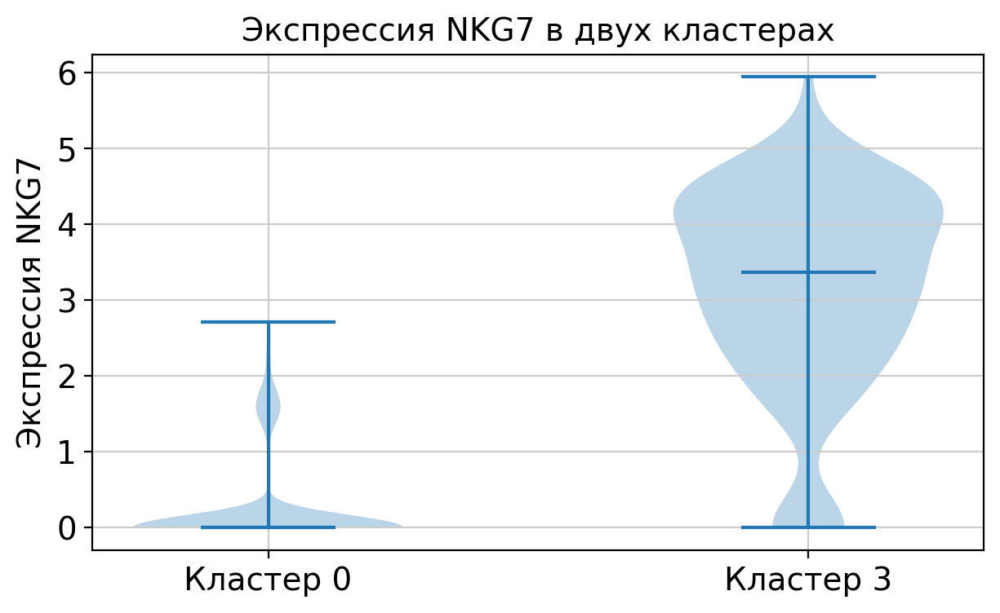

In [9]:
plt.figure(figsize=(7, 4))

plt.violinplot([A, B], showmedians=True)

plt.xticks([1, 2], ["Кластер 0", "Кластер 3"])
plt.ylabel("Экспрессия NKG7")
plt.title("Экспрессия NKG7 в двух кластерах")

plt.show()

---
### 1.2. Что получаем?

- `scores` для `method='wilcoxon'`: подписанная стандартизованная статистика рангового теста (не fold change).
- `pvals`: вероятность получить столь же экстремальную или более экстремальную статистику **при выполнении $H_0$**.
- `pvals_adj`: скорректированное значение при множественном тестировании.
- `logfoldchanges`: логарифм отношения оценённых уровней экспрессии, где знак отражает направление.
- `pct_nz_group` и `pct_nz_reference` (если доступны): доля клеток с ненулевой экспрессией в группе и в контроле.

$$\mathrm{log_2FC}=\log_2\frac{\mu_A}{\mu_B}, \quad \mu_A,\mu_B>0.$$

---
### 1.3. Поправка на множественные сравнения: Benjamini–Hochberg

Если мы тестируем 12 000 генов, при верной нулевой гипотезе и пороге FDR (это не p-value) 0.05 в среднем получим $12\,000\cdot 0.05=600$ ложноположительных результатов.

Метод BH контролирует **ожидаемую долю ложных отклонений среди отклонённых гипотез (FDR)** при соответствующих условиях. Мы сначала выбираем допустимый уровень FDR (например, 5%), а затем BH находит, какие гены можно объявить статистически значимыми, чтобы оставлять FDR на этом уровне. Можем получить для каждого гена соответствующую границу p-value чтобы он проходил границу FDR.

Затем мы хотим проверять на один заданный уровень FDR, а получить для каждого гена минимально допустимый FDR, тогда мы упорядовачиваем все p-value по своему значению и умножаем на коэффициент отражающий его ранговое положение относительно всех p-value. Затем идём от наименьшего и проверяем что у нас сохраняется неубывание по новым значениям. Если это правильно нарушается на шаге i то берем минимум между $i-1$ и $i$.

Упорядочим $p_{(1)}\le\ldots\le p_{(m)}$. Для ранга $i$ сначала считаем $p_{(i)}m/i$, затем обеспечиваем неубывание скорректированных значений по рангу через минимум по всем $j\ge i$, ограничивая результат единицей:

$$q_{(i)} = \min\left(1,\min_{j\ge i}\frac{m\,p_{(j)}}{j}\right).$$

### 1.4. Находим маркеры в клетках

**Важно: какое множество генов тестировать?** После отбора HVG в семинаре 1 **гены не были удалены**, лишь помечены `adata.var['highly_variable']`. Поэтому `adata.X` содержит и HVG, и остальные гены, что позволяет исследовать известные маркеры, не попавшие в HVG.

Расчёт `sc.tl.rank_genes_groups` ожидает **логарифмированные данные**, поэтому указываем `use_raw=False`, `layer=None`. `tie_correct=True` учитывает одинаковые значения для поправки дисперсии ранговой статистики.

In [10]:
sc.tl.rank_genes_groups(
    adata,
    groupby='leiden_1.0',
    method="wilcoxon",
    reference="rest",
    use_raw=False,
    layer=None,
    tie_correct=True,
    corr_method="benjamini-hochberg",
    pts=True, # вычисляет долю клеток, в которых экспрессируется каждый ген
    key_added='wilcoxon',
)

ranking genes


/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (


    finished (0:00:44)


/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/pytho

In [11]:
clusters = list(adata.obs['leiden_1.0'].cat.categories)
first_cluster = clusters[0]
markers_example = sc.get.rank_genes_groups_df(adata, group=first_cluster, key='wilcoxon')

In [12]:
print(f"Кластер {first_cluster}; строк: {len(markers_example)}")
display(markers_example.head(15))

Кластер 0; строк: 13714


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,LTB,23.282074,2.577841,6.735695e-120,9.237332e-116,0.985533,0.629257
1,IL32,20.799780,2.478875,4.347950e-96,2.981389e-92,0.933092,0.451319
2,IL7R,20.685240,2.427370,4.704312e-95,2.150498e-91,0.766727,0.305995
3,LDHB,19.324514,1.869246,3.341162e-83,1.145517e-79,0.945750,0.603357
4,CD3D,18.301039,2.142672,8.118718e-75,2.226802e-71,0.900542,0.419185
5,AQP3,18.214695,2.622822,3.946100e-74,9.019470e-71,0.424955,0.098801
6,TNFRSF4,17.268358,3.846911,8.142729e-67,1.240771e-63,0.211573,0.017746
7,TPT1,17.032158,0.706515,4.742340e-65,6.503645e-62,0.996383,0.983213
8,CD40LG,16.717585,2.796053,9.759444e-63,1.115342e-59,0.300181,0.052758
9,CD2,15.932926,1.953737,3.744189e-57,3.209238e-54,0.607595,0.241727


    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_1.0']`


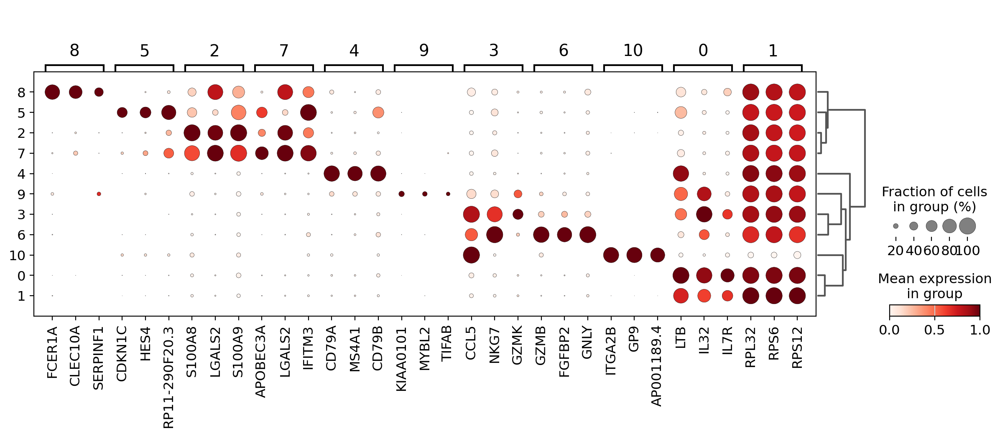

In [13]:
# Визуализируем по 3 наиболее высокоранжированных гена на кластер.
sc.pl.rank_genes_groups_dotplot(
    adata,
    key='wilcoxon',
    groupby='leiden_1.0',
    n_genes=3,
    use_raw=False,
    standard_scale="var",
)

### 1.6. Сравнение «один против всех» и «один против одного»

`reference='rest'` отвечает на вопрос «чем кластер A отличается от смеси всех остальных?». Но если два соседних T-клеточных кластера похожи, для их сравнения лучше **A vs B**, а не A vs rest.

In [14]:
group_A, group_B = "0","3"
sc.tl.rank_genes_groups(
    adata,
    groupby='leiden_1.0',
    groups=[group_A],
    reference=group_B,
    method="wilcoxon",
    tie_correct=True,
    use_raw=False,
    key_added="pairwise_0_3",
)

ranking genes
    finished (0:00:01)


/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:320: RuntimeWarning: invalid value encountered in divide
  scores = (


In [15]:
display(sc.get.rank_genes_groups_df(
    adata, group=group_A, key="pairwise_0_3"
).head(10))

print(f"Вычислено сравнение: cluster {group_A} vs cluster {group_B}")

,names,scores,logfoldchanges,pvals,pvals_adj
0,LTB,15.570868,2.451982,1.148398e-54,1.968642e-51
1,VIM,12.210079,1.372892,2.746232e-34,2.510788e-31
2,TPT1,11.931991,0.572724,8.062242e-33,6.142533e-30
3,LDHB,11.851615,1.382455,2.110839e-32,1.447402e-29
4,RPL32,11.696859,0.465427,1.322589e-31,8.637134e-29
5,TMSB10,11.047319,0.700616,2.258575e-28,1.407914e-25
6,RPL11,11.023608,0.408228,2.940305e-28,1.753189e-25
7,JUNB,10.349001,1.221219,4.228759e-25,2.230508e-22
8,RPL36,10.028109,0.760316,1.146930e-23,5.243001e-21
9,RPS25,9.917639,0.500961,3.489123e-23,1.495307e-20


Вычислено сравнение: cluster 0 vs cluster 3


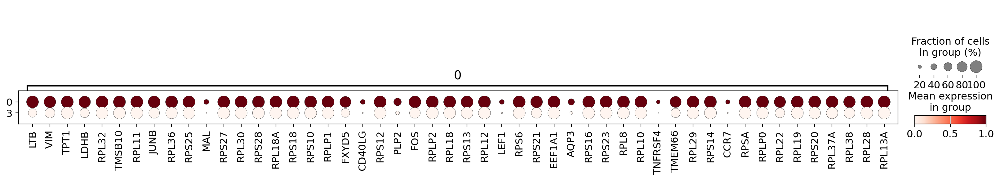

In [16]:
adata_pair = adata[
    adata.obs["leiden_1.0"].isin(["0", "3"])
].copy()

adata_pair.obs["leiden_1.0"] = (
    adata_pair.obs["leiden_1.0"]
    .cat.remove_unused_categories()
)
sc.pl.rank_genes_groups_dotplot(
    adata_pair,
    key="pairwise_0_3",
    groups=["0"],
    groupby="leiden_1.0",
    n_genes=50,
    use_raw=False,
    standard_scale="var",
    dendrogram=False,
)

---
## 2. Ручная аннотация клеточных кластеров

В основе ручной аннотации — сопоставление **набора согласованных маркеров** с биологическими знаниями.

| Возможная группа клеток | Проверяемые гены | Ограничения |
|---|---|---|
| T-лимфоциты | `CD3D`, `CD3E`, `TRAC` | T-клеточные типы можно делить дальше |
| CD4 T / наивные T | `IL7R`, `CCR7`, `LTB`, `CD4` | `IL7R`/`CCR7` не являются исключительно CD4-маркерами |
| CD8 / цитотоксические T | `CD8A`, `CD8B`, `CCL5`, `GZMK` | Пересечение с NK и активированными T-клетками |
| NK-клетки | `NKG7`, `GNLY`, `KLRD1`, `PRF1` | `NKG7` и `PRF1` встречаются в цитотоксических T |
| B-лимфоциты | `MS4A1`, `CD79A`, `CD79B` | Популяции плазмобластов могут отличаться |
| CD14+ моноциты | `LYZ`, `LST1`, `S100A8`, `S100A9`, `CD14` | Гранулоцитарные маркеры тоже могут встречаться |
| FCGR3A+ моноциты | `FCGR3A`, `LST1`, `MS4A7` | `FCGR3A` бывает и в NK |
| Дендритные клетки | `FCER1A`, `CD1C`, `CST3` | `CST3` не специфичен для DC |
| Тромбоциты/мегакариоцитарные элементы | `PPBP`, `PF4` | Могут отражать активированные тромбоциты или контаминацию |

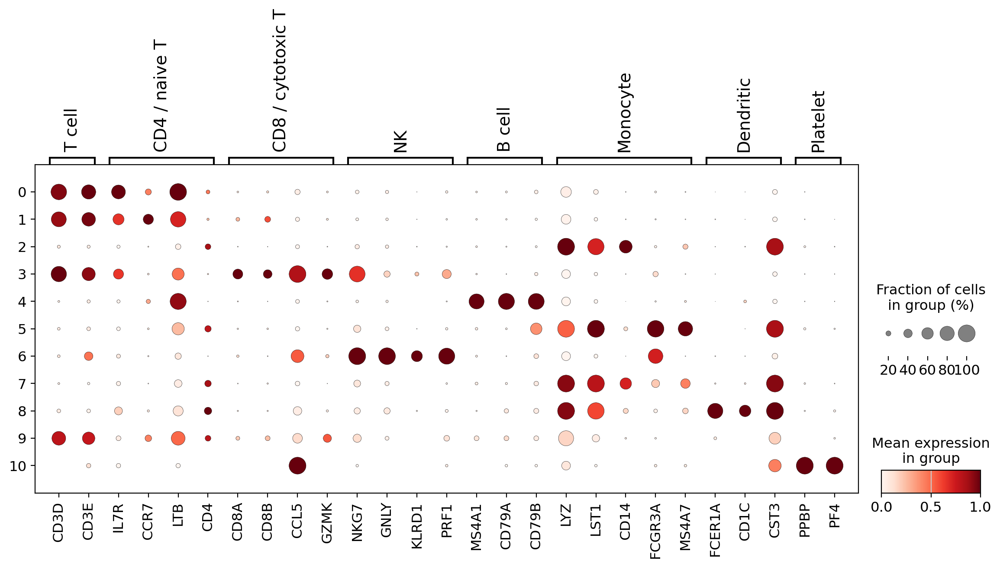

In [18]:
MARKERS = {
    "T cell": ["CD3D", "CD3E", "TRAC"],
    "CD4 / naive T": ["IL7R", "CCR7", "LTB", "CD4"],
    "CD8 / cytotoxic T": ["CD8A", "CD8B", "CCL5", "GZMK"],
    "NK": ["NKG7", "GNLY", "KLRD1", "PRF1"],
    "B cell": ["MS4A1", "CD79A", "CD79B"],
    "Monocyte": ["LYZ", "LST1", "CD14", "FCGR3A", "MS4A7"],
    "Dendritic": ["FCER1A", "CD1C", "CST3"],
    "Platelet": ["PPBP", "PF4"],
}
markers_present = {k: [g for g in genes if g in adata.var_names]
                   for k, genes in MARKERS.items()}
markers_present = {k: v for k, v in markers_present.items() if v}

sc.pl.dotplot(adata, var_names=markers_present, groupby='leiden_1.0',
              standard_scale="var", use_raw=False, figsize=(14, 5))

Как читать dotplot?

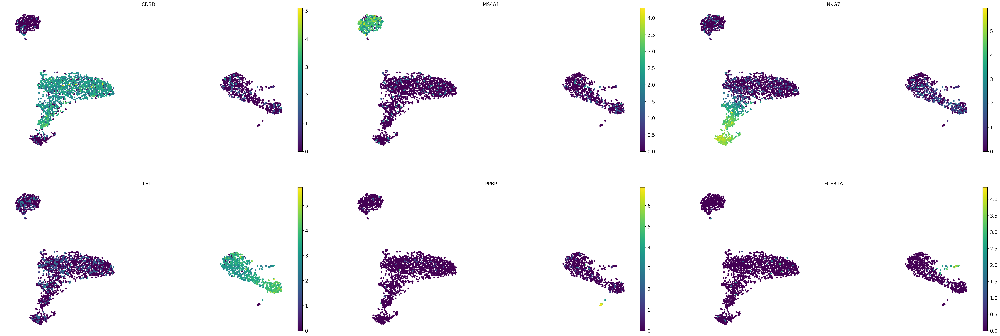

In [19]:
example_genes = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1", "PPBP", "FCER1A"] if g in adata.var_names]
sc.pl.umap(adata, color=example_genes, ncols=3, use_raw=False, size=100)

In [20]:
manual_annotations = {str(c): "Unassigned" for c in clusters}

manual_annotations.update({
    "0": "CD4 T cell",
    "1": "Naive CD4 T cell",
    "2": "CD14+ Monocyte",
    "3": "CD8 Cytotoxic T cell",
    "4": "B cell",
    "5": "FCGR3A+ Monocyte",
    "6": "NK cell",
    "7": "CD14+ Monocyte",
    "8": "Dendritic cell (cDC)",
    "9": "T cell (memory-like)",
    "10": "Platelet",
})

unknown_keys = set(manual_annotations).difference(map(str, clusters))

adata.obs["manual_cell_type"] = pd.Categorical(
    adata.obs['leiden_1.0'].astype(str).map(manual_annotations).fillna("Unassigned")
)
print(pd.DataFrame({"cluster": list(manual_annotations),
                    "manual_cell_type": list(manual_annotations.values())}))

   cluster      manual_cell_type
0        0            CD4 T cell
1        1      Naive CD4 T cell
2        2        CD14+ Monocyte
3        3  CD8 Cytotoxic T cell
4        4                B cell
5        5      FCGR3A+ Monocyte
6        6               NK cell
7        7        CD14+ Monocyte
8        8  Dendritic cell (cDC)
9        9  T cell (memory-like)
10      10              Platelet


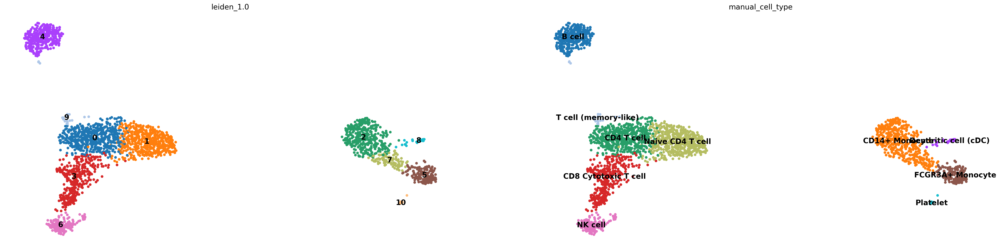

In [21]:
sc.pl.umap(adata, color=['leiden_1.0', "manual_cell_type"], ncols=2, size=100, legend_loc="on data")

---
## 3. Автоматическая аннотация с CellTypist

Существуют уже размеченные аннотации, которые можно использовать. Попробуем использовать **обученную модель классификации** Celltypist.

На концептуальном уровне логистическая регрессия оценивает для класса $k$ линейную функцию признаков:

$$z_k = b_k + \sum_{g=1}^{G} w_{kg}x_g.$$

Далее из оценок формируют прогноз класса (в упрощённой бинарной задаче $\sigma(z)=1/(1+e^{-z})$). 

Модель обучена на **размеченном референсе**, поэтому перенос её предсказаний ограничен и зависит от похожести клеточных типов, биологических состояний, платформ и референса.

Модель `Immune_All_Low.pkl` предназначена для иммунных клеток. CellTypist ожидает `log1p`-нормализованную экспрессию с суммой 10 000 до логарифмирования и символы генов — именно тот формат, который мы получили в первом семинаре.

In [22]:
HAS_CELLTYPIST = True

if importlib.util.find_spec("celltypist") is None:
    print("CellTypist не установлен. Установите его в sc_pbmc или пропустите раздел 3.")
else:
    try:
        import celltypist
        # Используем локальную модель при наличии — это удобно на сервере без интернета.
        try:
            model = celltypist.models.Model.load("Immune_All_Low.pkl")
        except Exception:
            celltypist.models.download_models(model="Immune_All_Low.pkl")
            model = celltypist.models.Model.load("Immune_All_Low.pkl")

        prediction = celltypist.annotate(adata.copy(), model=model,
                                       majority_voting=False)
        celltypist_table = prediction.predicted_labels.reindex(adata.obs_names)
        assert celltypist_table["predicted_labels"].notna().all(), "Потеряна часть клеток"
        adata.obs["celltypist"] = pd.Categorical(
            celltypist_table["predicted_labels"].astype(str).to_numpy()
        )
        if "conf_score" in celltypist_table:
            adata.obs["celltypist_confidence"] = (
                celltypist_table["conf_score"].astype(float).to_numpy()
            )
        HAS_CELLTYPIST = True
        display(adata.obs["celltypist"].value_counts().to_frame("cells"))
    except Exception as error:
        print("CellTypist пропущен:", type(error).__name__, str(error)[:300])

🔬 Input data has 2638 cells and 13714 genes
🔗 Matching reference genes in the model


Используем локальную модель CellTypist


🧬 4178 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


Автоматическая аннотация готова:


,cells
celltypist,
Tcm/Naive helper T cells,636
Classical monocytes,393
B cells,340
Non-classical monocytes,229
Tcm/Naive cytotoxic T cells,215
Tem/Effector helper T cells,188
CD16+ NK cells,149
Tem/Trm cytotoxic T cells,110
Regulatory T cells,103


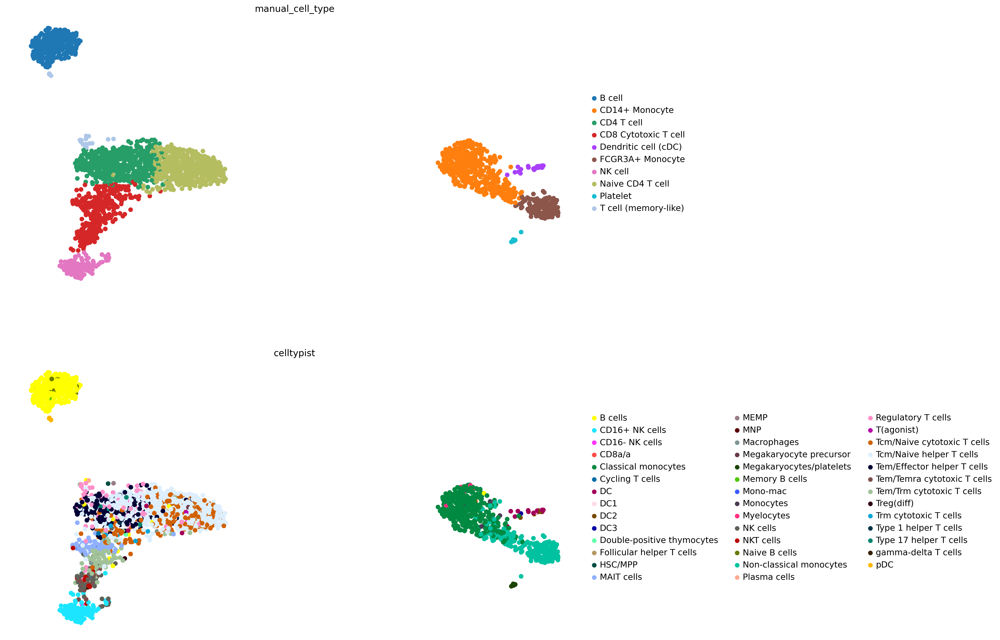

In [23]:
sc.pl.umap(adata, color=["manual_cell_type", "celltypist"],
           ncols=1, size=200)

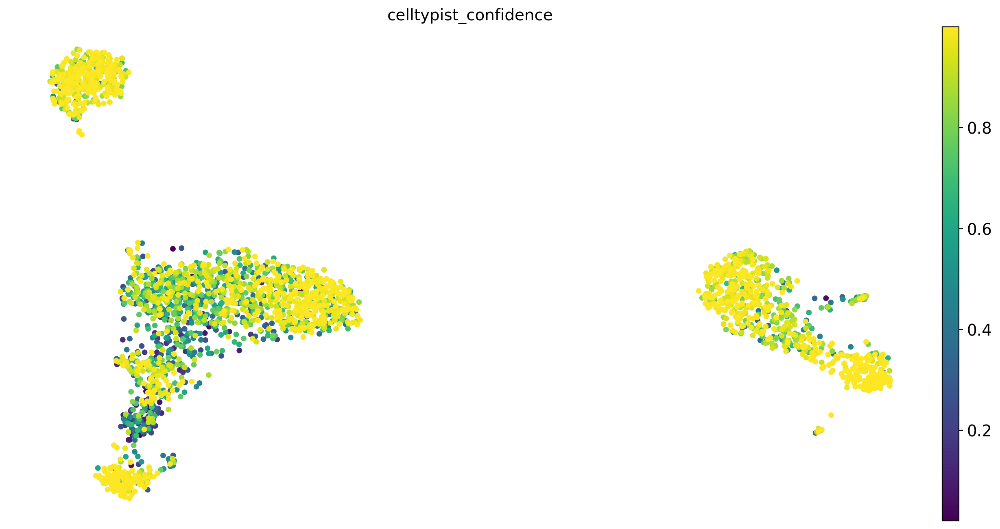

In [24]:
# Получаем confidence для каждой клетки
adata.obs["celltypist_confidence"] = (
    prediction.probability_matrix
    .max(axis=1)
    .reindex(adata.obs_names)
    .astype(float)
)

# Строим UMAP
sc.pl.umap(
    adata,
    color="celltypist_confidence",
    cmap="viridis",
    size=100
)

In [25]:
display(pd.crosstab(adata.obs['leiden_1.0'], adata.obs["celltypist"],
                    rownames=["Leiden"], colnames=["CellTypist"]))

CellTypist,B cells,CD16+ NK cells,CD16- NK cells,CD8a/a,Classical monocytes,Cycling T cells,DC,DC1,DC2,DC3,...,Tcm/Naive helper T cells,Tem/Effector helper T cells,Tem/Temra cytotoxic T cells,Tem/Trm cytotoxic T cells,Treg(diff),Trm cytotoxic T cells,Type 1 helper T cells,Type 17 helper T cells,gamma-delta T cells,pDC
Leiden,,,,,,,,,,,,,,,,,,,,,
0,2,0,0,0,0,0,1,0,0,0,...,271,169,0,0,1,2,1,5,0,0
1,4,0,1,0,0,0,1,0,0,0,...,342,10,0,5,0,0,0,0,0,0
2,1,0,1,0,342,0,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,8,0,1,0,1,1,0,0,0,...,21,8,17,102,2,8,2,0,1,0
4,328,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
5,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,141,2,0,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,0,0
7,0,0,0,0,48,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,2,0,14,1,8,1,...,0,0,0,0,0,0,0,0,0,1


---
## 4. Генные программы

`sc.tl.score_genes()` вычисляет для каждой клетки разность между средней экспрессией заданной ген ной сигнатуры и средней экспрессией контрольных генов, отобранных с учётом уровня экспрессии:

$$S(c)=\frac{1}{|G|}\sum_{g\in G}x_{cg} - \frac{1}{|G_0|}\sum_{h\in G_0}x_{ch}.$$

Здесь $G$ — целевая программа, $G_0$ — набор подобранных контрольных генов.

computing score 'cytotoxic_score'
    finished (0:00:00)


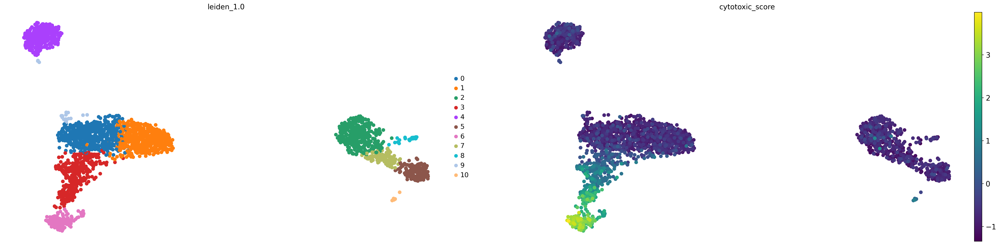

In [26]:
cytotoxic_genes = [g for g in ["NKG7", "GNLY", "GZMB", "PRF1", "CCL5"]
                   if g in adata.var_names]

sc.tl.score_genes(
    adata,
    gene_list=cytotoxic_genes,
    score_name="cytotoxic_score",
    use_raw=False,
    random_state=42,
)
sc.pl.umap(adata, color=['leiden_1.0', "cytotoxic_score"], ncols=2, size=200)

In [27]:
score_summary = (adata.obs.groupby('leiden_1.0', observed=True)["cytotoxic_score"]
                 .agg(["mean", "median", "count"])
                 .sort_values("mean", ascending=False))
display(score_summary)

,mean,median,count
leiden_1.0,,,
6,2.632246,2.718706,156
3,0.866440,0.759517,347
10,0.487299,0.476835,12
9,-0.654455,-0.816104,21
1,-0.755196,-0.843985,536
4,-0.793460,-0.874310,341
0,-0.801649,-0.898013,553
2,-0.808824,-0.858775,378
5,-0.900530,-0.910399,157


---
## 5. Сохранение результатов

In [29]:
path_annotated = DATA_DIR / "pbmc3k_after_annotation.h5ad"
path_tcells = DATA_DIR / "pbmc3k_Tcells_subclustered.h5ad"
path_table = DATA_DIR / "pbmc3k_manual_cluster_labels.csv"

adata.write_h5ad(path_annotated, compression="gzip")
adata.write_h5ad(path_tcells, compression="gzip")
pd.DataFrame({"cluster": list(manual_annotations.keys()),
              "manual_cell_type": list(manual_annotations.values())}).to_csv(path_table, index=False)

print("Сохранено:")
for path in [path_annotated, path_tcells, path_table,
             DATA_DIR / "pbmc3k_markers_all.csv", DATA_DIR / "pbmc3k_markers_filtered.csv"]:
    print(" ", path, "(", round(path.stat().st_size / 1024**2, 2), "МБ)")

Сохранено:
  data/pbmc3k_after_annotation.h5ad ( 25.68 МБ)
  data/pbmc3k_Tcells_subclustered.h5ad ( 25.68 МБ)
  data/pbmc3k_manual_cluster_labels.csv ( 0.0 МБ)
  data/pbmc3k_markers_all.csv ( 15.26 МБ)
  data/pbmc3k_markers_filtered.csv ( 0.42 МБ)


## 8. **Итоговая цепочка анализа:**

`counts → QC → normalize/log1p → HVG → PCA → kNN → Leiden → Аннотация по маркерам  → Автоматическая аннотация (если возможна) → Аннотация по группе генов (score_genes) → субкластеризация → И так по кругу пока не найдем биологию`

![](after.jpg)

## 9. Самостоятельная + домашняя работа

**Задача:** самостоятельно провести полный анализ scRNA-seq данных: от контроля качества и фильтрации клеток до кластеризации, аннотации клеточных типов и анализа генных программ.

**Формат работы:** индивидуально или в парах. Можно выбрать любой открытый scRNA-seq датасет. Рекомендуется использовать данные, содержащие несколько различных клеточных популяций.

### Задание 1. Выбор данных и контроль качества (QC)

1. Найдите открытый scRNA-seq датасет и загрузите его в `AnnData`.
2. Кратко опишите выбранные данные:
   - Какие клетки или ткани исследовались?
   - Какой биологический вопрос изучали авторы?
   - Сколько клеток и генов содержится в датасете?
3. Рассчитайте основные показатели QC: `total_counts`, `n_genes_by_counts`, `pct_counts_mt`.
4. Постройте графики распределения этих показателей (violin plots, scatter plots).
5. Выберите пороги фильтрации и удалите клетки низкого качества, а также редко обнаруживаемые гены.
6. Покажите, сколько клеток и генов осталось после фильтрации.

**Обязательно объясните, почему выбрали именно такие пороги и какие клетки они позволяют исключить.**

### Задание 2. Нормализация и высоковариабельные гены (HVG)

1. Выполните нормализацию и логарифмирование экспрессии.
2. Найдите высоковариабельные гены с помощью `sc.pp.highly_variable_genes()`.
3. Постройте график HVG.
4. Покажите, сколько генов было выбрано.
5. Выведите 10 наиболее высоковариабельных генов и попробуйте выяснить, какие функции они выполняют.

**Вопрос:** зачем мы выбираем HVG и почему не обязательно использовать все гены для PCA и кластеризации?

### Задание 3. PCA и кластеризация

1. Выполните PCA, используя HVG.
2. Постройте график PCA и график объяснённой дисперсии (`sc.pl.pca_variance_ratio()`).
3. Постройте граф соседства клеток и вычислите UMAP.
4. Выполните кластеризацию Leiden с двумя различными значениями `resolution`, например 0.3 и 1.0.
5. Постройте два UMAP с результатами кластеризации.
6. Сравните количество и размеры получившихся кластеров.

**Вопросы:**
- Как изменение `resolution` влияет на число кластеров?
- Какие кластеры разделились при увеличении разрешения?
- Обязательно ли каждый получившийся кластер соответствует отдельному типу клеток?

### Задание 4. Ручная аннотация клеток

Выберите одно из двух разрешений Leiden для дальнейшей работы.

1. Найдите маркерные гены кластеров с помощью `sc.tl.rank_genes_groups()`.
2. Для каждого кластера рассмотрите наиболее высокоранжированные гены, их экспрессию и долю экспрессирующих клеток.
3. Найдите в литературе или специализированных базах известные маркеры предполагаемых клеточных типов.
4. Постройте `dotplot` и UMAP с экспрессией выбранных маркеров.
5. Присвойте каждому кластеру предполагаемый клеточный тип и сохраните результаты в `adata.obs["manual_cell_type"]`.

Составьте таблицу:

| Кластер | Предполагаемый клеточный тип | Маркерные гены | Обоснование |
|---|---|---|---|
| 0 | ... | ... | ... |
| 1 | ... | ... | ... |
| ... | ... | ... | ... |

**Важно:** если клеточный тип невозможно уверенно определить, используйте `Unknown` или более общее название популяции. Необязательно каждому кластеру присваивать уникальный клеточный тип.

### Задание 5. Автоматическая аннотация

1. Найдите инструмент автоматической аннотации клеточных типов или используйте `CellTypist`.
2. Выберите подходящую референсную модель для вашего датасета.
3. Выполните автоматическую аннотацию клеток.
4. Постройте UMAP с результатами автоматической аннотации.
5. Сравните результаты с вашей ручной аннотацией.

Для сравнения постройте таблицу сопряжённости (`pd.crosstab()`), показывающую, какие автоматические аннотации соответствуют каждому кластеру и каждому типу из ручной аннотации.

**Вопросы:**
- Для каких кластеров ручная и автоматическая аннотации совпали?
- Где наблюдаются расхождения?
- С чем они могут быть связаны?
- Какую аннотацию вы считаете более обоснованной и почему?

Если выбранный инструмент не поддерживает ваш вид или ткань, объясните ограничение и попробуйте найти подходящую альтернативу.

### Задание 6. Субкластеризация

Выберите один из полученных кластеров, который потенциально содержит несколько клеточных подтипов или функциональных состояний.

1. Создайте отдельный `AnnData`, содержащий только клетки выбранного кластера.
2. Повторите необходимые этапы анализа для этого подмножества: отбор HVG, PCA, построение графа соседства, UMAP и Leiden.
3. Постройте UMAP полученных субкластеров.
4. Найдите маркерные гены новых субкластеров.
5. Попробуйте определить более узкие клеточные типы или состояния на основании маркеров.

**Вопросы:**
- Удалось ли разделить исходную популяцию на биологически интерпретируемые субпопуляции?
- Какие гены отличают новые субкластеры?
- Почему эти различия могли быть незаметны при первоначальной кластеризации всех клеток?

Если убедительных субпопуляций обнаружить не удалось, объясните возможные причины.

### Задание 7. Генные программы (Gene Scores)

Выберите **три набора генов**, соответствующих различным биологическим функциям или клеточным состояниям.

Например:
- Цитотоксичность: `NKG7`, `PRF1`, `GZMB`, `GNLY`.
- Интерфероновый ответ: `ISG15`, `IFIT1`, `MX1`, `IFI6`.
- Пролиферация: `MKI67`, `TOP2A`, `PCNA`, `TYMS`.

Можно использовать другие программы, более подходящие для выбранных данных. Укажите, откуда взяты наборы генов.

1. Рассчитайте оценки всех трёх программ с помощью `sc.tl.score_genes()`.
2. Постройте UMAP, раскрашенные по значениям каждого score.
3. Постройте violin plots распределения scores по аннотированным клеточным типам.
4. Определите, в каких клеточных популяциях каждая программа выражена сильнее всего.
5. Сравните полученные результаты с аннотацией клеточных типов.

**Главный вопрос:** как информацию о генных программах можно использовать для уточнения ручной аннотации клеток?

Приведите конкретные примеры из своих данных: какие программы помогают различать клеточные типы, подтипы или функциональные состояния?

Помните, что высокий gene score отражает относительную экспрессию сигнатуры, но сам по себе не доказывает выполнение биологической функции.

### Задание 8. Итоговые результаты и выводы

Подготовьте итоговую визуализацию и краткое заключение.

В работе должны присутствовать:

- UMAP с исходной кластеризацией при двух разрешениях.
- UMAP с ручной аннотацией клеточных типов.
- UMAP с автоматической аннотацией.
- Dotplot основных маркерных генов.
- UMAP субкластеров выбранной популяции.
- Три UMAP с оценками генных программ.
- Сравнение ручной и автоматической аннотации.

**Ответьте в заключении:**

1. Какие основные клеточные популяции удалось обнаружить?
2. Какие маркерные гены позволили их идентифицировать?
3. Насколько согласуются ручная и автоматическая аннотации?
4. Что удалось обнаружить при субкластеризации?
5. Какие дополнительные сведения о клетках дали генные программы?

---

### Что сдавать

**Один Jupyter Notebook (`.ipynb`)**, содержащий весь воспроизводимый анализ, графики и пояснения к результатам.

В начале ноутбука укажите название датасета, ссылку на источник и участников работы.

Каждый этап должен сопровождаться кратким объяснением: **что было сделано, зачем и какой результат получен**.

Допускается работа в парах (не более двух человек). В этом случае сдаётся один общий ноутбук с указанием обоих участников.

---
# 9. Решение самостоятельной работы

| | |
|---|---|
| **Датасет** | *10k PBMCs from a Healthy Donor — Gene Expression and Cell Surface Protein* (10x Genomics, Chromium Single Cell 3′ v3, CITE-seq, антитела TotalSeq-B) |
| **Источник** | 10x Genomics, публичные датасеты (`pbmc_10k_protein_v3`). Используем версию из репозитория scvi-tools, подготовленную для статьи totalVI (Gayoso et al., *Nat. Methods* 2021): https://github.com/YosefLab/scVI-data/raw/master/pbmc_10k_protein_v3.h5ad |
| **Референс для автоаннотации** | Monaco et al., *Cell Rep.* 2019 — bulk RNA-seq 29 отсортированных популяций иммунных клеток крови; файлы из релиза https://github.com/kanaverse/singlepp-references/releases/tag/2023-04-28 |
| **Участники** | *ФИО участника(ов) — заполнить* |

Раздел полностью самостоятельный: свои импорты, своя папка `data/hw`, свой объект `pbmc` (переменная `adata` из семинара не перезаписывается).

Дополнительно к окружению `sc_pbmc` нужен пакет SingleR для Python:

```bash
pip install singler
```

In [1]:
from pathlib import Path
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
from scipy.sparse import csr_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message="invalid value encountered in divide")
sc.settings.verbosity = 1
sc.set_figure_params(dpi=70, figsize=(5, 4.5), frameon=False)
np.random.seed(42)

HW_DIR = Path("data") / "hw"
HW_DIR.mkdir(parents=True, exist_ok=True)

def download(url, path):
    # Скачиваем файл, только если его ещё нет локально.
    path = Path(path)
    if not path.exists():
        print("Скачиваю", path.name, "...")
        urllib.request.urlretrieve(url, path)
    return path

print("scanpy", sc.__version__, "| anndata", ad.__version__)

scanpy 1.12.5 | anndata 0.13.4


## Задание 1. Выбор данных и контроль качества

**Что за данные.** Мононуклеарные клетки периферической крови (PBMC) одного здорового донора, ~10 000 клеток по паспорту 10x. Это CITE-seq: для каждой клетки одновременно измерены транскриптом и уровни 14 поверхностных белков (CD3, CD4, CD8a, CD14, CD16, CD19, CD56, CD45RA, CD45RO, CD127, CD25, PD-1, TIGIT, CD15).

**Биологический вопрос.** Отдельного биологического вопроса у этого набора нет: это демонстрационный датасет 10x, который стал стандартным бенчмарком для методов (в частности, totalVI). Для нас это удобно: в крови есть все основные лимфоидные и миелоидные популяции, а белковые метки дают **независимую проверку** аннотации, сделанной по РНК.

Белки мы не используем для кластеризации — только как контроль в заданиях 4 и 6.

In [2]:
raw_path = download(
    "https://github.com/YosefLab/scVI-data/raw/master/pbmc_10k_protein_v3.h5ad",
    HW_DIR / "pbmc_10k_protein_v3.h5ad",
)
src = sc.read_h5ad(raw_path)

# Собираем «чистый» AnnData: сырые UMI-counts + белки (ADT) отдельно в .obsm
pbmc = ad.AnnData(
    X=csr_matrix(src.X.astype(np.float32)),
    obs=pd.DataFrame(index=src.obs_names),
    var=pd.DataFrame(index=src.var_names),
)
pbmc.var_names_make_unique()
pbmc.obsm["adt"] = pd.DataFrame(
    src.obsm["protein_expression"],
    index=src.obs_names,
    columns=[p.replace("_TotalSeqB", "") for p in src.uns["protein_names"]],
)
del src

print(pbmc)
print(f"Клеток: {pbmc.n_obs}, генов: {pbmc.n_vars}, белков: {pbmc.obsm['adt'].shape[1]}")
print("Белки:", ", ".join(pbmc.obsm["adt"].columns))
print("Это целые counts?", np.allclose(pbmc.X.data, np.round(pbmc.X.data)))

AnnData object with n_obs × n_vars = 6855 × 16727
    obsm: 'adt'
    layers: None (.X)
Клеток: 6855, генов: 16727, белков: 14
Белки: CD3, CD4, CD8a, CD14, CD15, CD16, CD56, CD19, CD25, CD45RA, CD45RO, PD-1, TIGIT, CD127
Это целые counts? True


In [3]:
pbmc.var["mt"] = pbmc.var_names.str.startswith("MT-")
pbmc.var["ribo"] = pbmc.var_names.str.match(r"^RP[SL]")
sc.pp.calculate_qc_metrics(pbmc, qc_vars=["mt", "ribo"], percent_top=None,
                           log1p=False, inplace=True)

qc_cols = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]
display(pbmc.obs[qc_cols].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(1))

,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo
count,6855.0,6855.0,6855.0,6855.0
mean,4154.2,1505.1,5.9,27.0
std,2009.7,489.4,1.6,10.1
min,525.0,272.0,0.8,0.8
1%,1539.1,788.0,2.7,11.0
5%,2223.4,957.7,3.4,13.2
50%,3574.0,1374.0,5.8,27.4
95%,8044.3,2505.0,8.7,42.3
99%,11908.4,3114.8,9.6,44.7
max,18874.0,4260.0,10.0,48.5


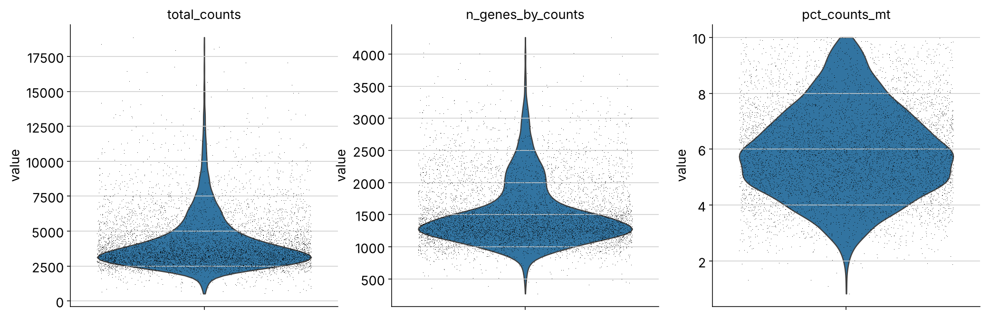

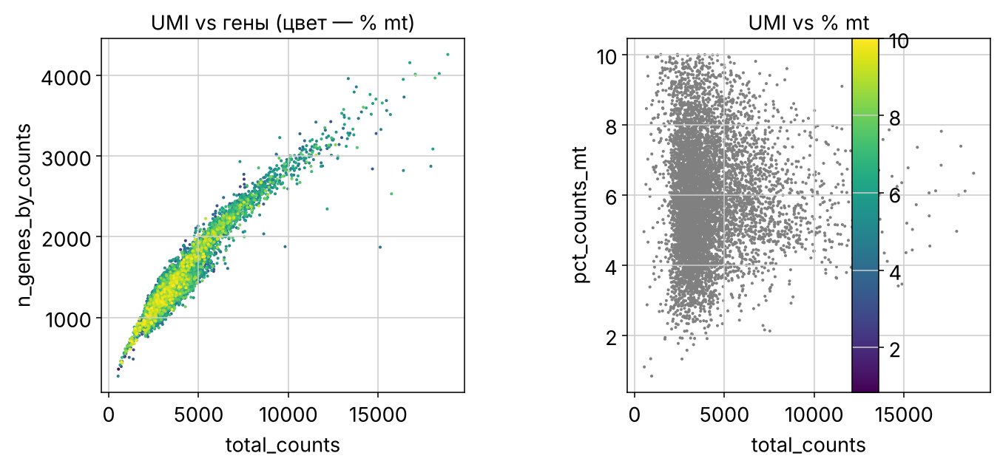

In [4]:
sc.pl.violin(pbmc, ["total_counts", "n_genes_by_counts", "pct_counts_mt"],
             multi_panel=True, jitter=0.4, size=0.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sc.pl.scatter(pbmc, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt",
              ax=axes[0], show=False, title="UMI vs гены (цвет — % mt)")
sc.pl.scatter(pbmc, x="total_counts", y="pct_counts_mt",
              ax=axes[1], show=False, title="UMI vs % mt")
fig.subplots_adjust(wspace=0.45)
plt.show()

Минимальный `pct_counts_mt` в таблице ≈ 0,8 %, максимальный — ровно 10 %, гены встречаются минимум в 4 клетках. Значит, авторы версии scvi-tools уже провели **предварительную фильтрацию** (по-видимому, `pct_mt < 10 %`). Мы всё равно делаем собственный QC: ищем выбросы по числу генов/UMI и **дублеты**.

Для ориентира посчитаем «робастные» границы median ± 5·MAD (MAD — медианное абсолютное отклонение), а дублеты оценим Scrublet — он симулирует искусственные дублеты из пар клеток и для каждой реальной клетки считает, насколько её окружение похоже на симулированные дублеты.

In [5]:
def mad_bounds(x, n_mads=5):
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    return med - n_mads * mad, med + n_mads * mad

mad_table = pd.DataFrame(
    {col: mad_bounds(pbmc.obs[col].to_numpy()) for col in ["total_counts", "n_genes_by_counts", "pct_counts_mt"]},
    index=["нижняя граница (median − 5·MAD)", "верхняя граница (median + 5·MAD)"],
).round(1)
display(mad_table)

sc.pp.scrublet(pbmc, random_state=0)
print("Scrublet: предсказанных дублетов —", int(pbmc.obs["predicted_doublet"].sum()))
print("Порог doublet_score:", round(pbmc.uns["scrublet"]["threshold"], 3))

,total_counts,n_genes_by_counts,pct_counts_mt
нижняя граница (median − 5·MAD),-451.0,304.0,0.3
верхняя граница (median + 5·MAD),7599.0,2444.0,11.2


Scrublet: предсказанных дублетов — 5
Порог doublet_score: 0.449


In [6]:
MIN_GENES, MAX_GENES = 500, 3500
MAX_COUNTS = 15000
MAX_MT = 10
MIN_CELLS = 10

obs = pbmc.obs
filters = {
    f"n_genes < {MIN_GENES}": obs["n_genes_by_counts"] < MIN_GENES,
    f"n_genes > {MAX_GENES}": obs["n_genes_by_counts"] > MAX_GENES,
    f"total_counts > {MAX_COUNTS}": obs["total_counts"] > MAX_COUNTS,
    f"pct_mt >= {MAX_MT}": obs["pct_counts_mt"] >= MAX_MT,
    "дублет (Scrublet)": obs["predicted_doublet"].astype(bool),
}
display(pd.Series({k: int(v.sum()) for k, v in filters.items()}, name="удаляется клеток").to_frame())

bad = np.logical_or.reduce(list(filters.values()))
n_cells_before, n_genes_before = pbmc.shape
pbmc = pbmc[~bad].copy()
sc.pp.filter_genes(pbmc, min_cells=MIN_CELLS)

print(f"Клетки: {n_cells_before} → {pbmc.n_obs} (удалено {n_cells_before - pbmc.n_obs})")
print(f"Гены:   {n_genes_before} → {pbmc.n_vars} (удалено {n_genes_before - pbmc.n_vars})")

,удаляется клеток
n_genes < 500,9
n_genes > 3500,25
total_counts > 15000,18
pct_mt >= 10,2
дублет (Scrublet),5


Клетки: 6855 → 6808 (удалено 47)
Гены:   16727 → 14730 (удалено 1997)


**Почему такие пороги.**

- `n_genes_by_counts ≥ 500`. Нижняя граница по MAD отрицательная, т.е. бесполезна, поэтому порог выбран по графику: основная масса клеток лежит выше ~800 генов (1-й перцентиль), а клетки с < 500 генами — это пустые капли с фоновой («ambient») РНК или разрушенные клетки. Для химии 10x v3 500 генов — консервативный порог, он убирает лишь единичные клетки.
- `n_genes_by_counts ≤ 3500` и `total_counts ≤ 15 000`. Верхний хвост распределения (выше 99-го перцентиля и выше median + 5·MAD) — кандидаты в **дублеты**: две клетки в одной капле дают примерно вдвое больше UMI и генов.
- `pct_counts_mt < 10 %`. Высокая доля митохондриальных транскриптов — признак повреждённой клетки, из которой цитоплазматическая мРНК вытекла, а митохондрии остались. Этот фильтр уже применён авторами, мы его просто фиксируем явно. Жёстче не режем: в PBMC моноциты в норме имеют больше mt-РНК, чем лимфоциты, и порог 5 % (как в PBMC3k) выбил бы их непропорционально.
- **Scrublet** дополнительно убирает дублеты внутри «нормального» диапазона UMI (например, гетеротипичные Т+моноцит).
- Гены, детектируемые меньше чем в 10 клетках, не несут информации для кластеризации и маркеров, поэтому удаляются.

## Задание 2. Нормализация и высоковариабельные гены (HVG)

Порядок такой же, как в семинаре: сначала сохраняем сырые counts в `layers['counts']` и считаем HVG методом `seurat_v3` — он моделирует связь «среднее–дисперсия» именно на **сырых counts**. Затем `normalize_total` (10 000 UMI на клетку) и `log1p` в `.X`.

Выбрано HVG: 2000 из 14730


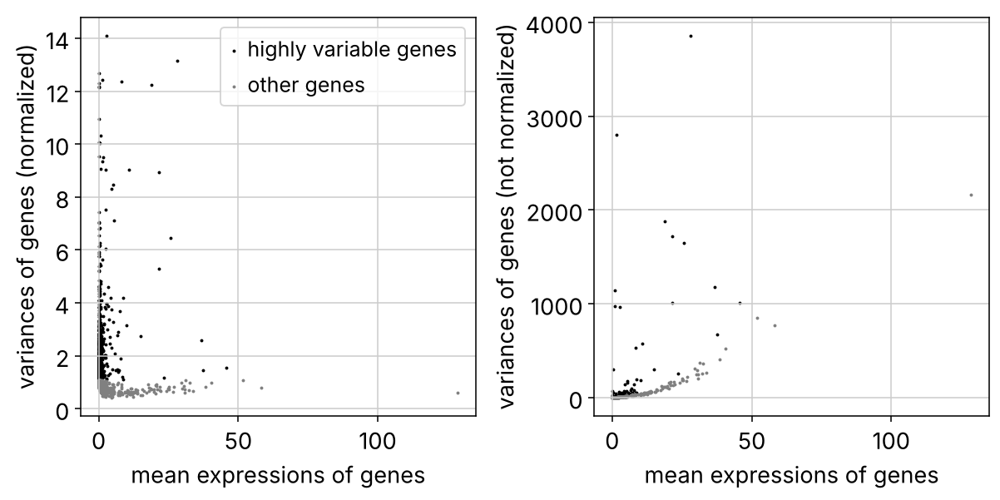

In [7]:
pbmc.layers["counts"] = pbmc.X.copy()

sc.pp.highly_variable_genes(pbmc, layer="counts", flavor="seurat_v3", n_top_genes=2000)

sc.pp.normalize_total(pbmc, target_sum=1e4)
sc.pp.log1p(pbmc)

print("Выбрано HVG:", int(pbmc.var["highly_variable"].sum()), "из", pbmc.n_vars)
sc.pl.highly_variable_genes(pbmc)

In [8]:
top10_hvg = (pbmc.var[pbmc.var["highly_variable"]]
             .sort_values("highly_variable_rank")
             .head(10)[["highly_variable_rank", "means", "variances_norm"]])
display(top10_hvg.round(3))

,highly_variable_rank,means,variances_norm
index,,,
IGKC,0.0,2.799,14.100
S100A9,1.0,28.162,13.134
FCER1A,2.0,0.122,12.690
IGHM,3.0,1.281,12.416
HLA-DRA,4.0,8.324,12.350
CDKN1C,5.0,0.135,12.311
S100A8,6.0,18.781,12.228
C1QA,7.0,0.085,12.180
PTGDS,8.0,0.155,12.145


**Функции 10 самых вариабельных генов.** Почти все они — маркеры конкретных типов клеток, то есть их вариабельность объясняется тем, что ген «включён» в одной популяции и «выключен» в остальных:

| Ген | Функция | Где экспрессируется в PBMC |
|---|---|---|
| `IGKC` | константная область лёгкой цепи κ иммуноглобулина | B-клетки, плазмобласты |
| `S100A9`, `S100A8` | субъединицы кальпротектина — антимикробный белок, сигнал воспаления (DAMP) | классические моноциты |
| `FCER1A` | α-цепь высокоаффинного рецептора IgE | дендритные клетки cDC2, базофилы |
| `IGHM` | тяжёлая цепь IgM | наивные B-клетки |
| `HLA-DRA` | α-цепь MHC класса II, презентация антигена CD4 T-клеткам | B-клетки, моноциты, DC |
| `CDKN1C` | p57^KIP2, ингибитор циклин-зависимых киназ | неклассические CD16⁺ моноциты |
| `C1QA` | компонент C1q комплемента | неклассические моноциты |
| `PTGDS` | простагландин-D2-синтаза | NK-клетки, pDC |
| `LYPD2` | белок семейства Ly6/uPAR | неклассические моноциты |

**Зачем HVG.** Большинство из ~15 000 генов либо почти не детектируются, либо экспрессируются примерно одинаково во всех клетках (домашнего хозяйства), и их разброс — в основном технический шум пуассоновского сэмплинга UMI. Если подать их в PCA, шум «размывает» главные компоненты. 2000 HVG концентрируют биологический сигнал (различия между типами клеток), ускоряют расчёты и уменьшают память. При этом сами гены из матрицы **не удаляются** — для поиска маркеров и gene scores мы используем все гены.

## Задание 3. PCA и кластеризация

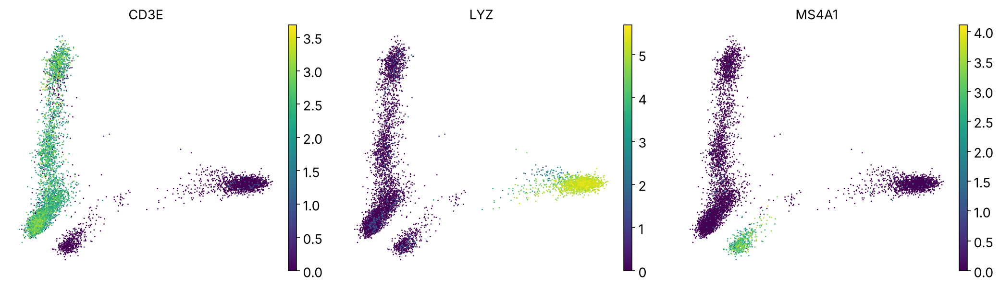

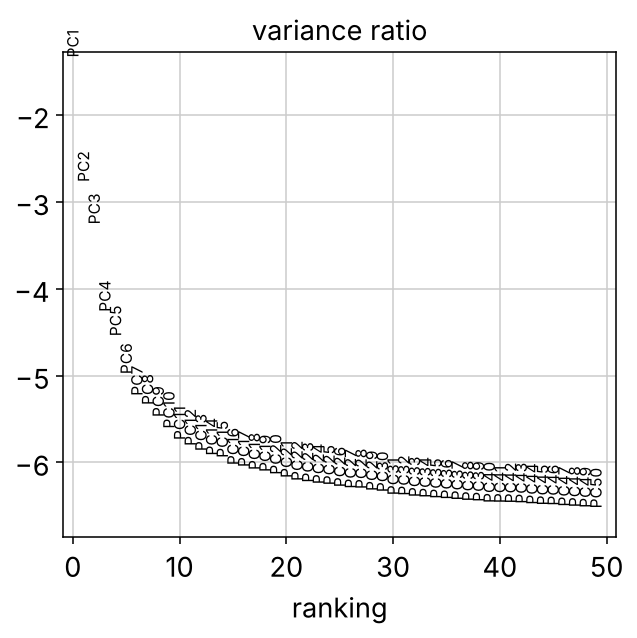

Доля дисперсии, PC1–10: [0.262 0.063 0.038 0.014 0.011 0.007 0.005 0.005 0.004 0.004]
Накопленная доля дисперсии в 30 PC: 0.457


In [9]:
sc.tl.pca(pbmc, n_comps=50, mask_var="highly_variable", random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, gene in zip(axes, ["CD3E", "LYZ", "MS4A1"]):
    sc.pl.pca(pbmc, color=gene, ax=ax, show=False, use_raw=False, size=8)
plt.tight_layout()
plt.show()

sc.pl.pca_variance_ratio(pbmc, n_pcs=50, log=True)
print("Доля дисперсии, PC1–10:", np.round(pbmc.uns["pca"]["variance_ratio"][:10], 3))
print("Накопленная доля дисперсии в 30 PC:", round(pbmc.uns["pca"]["variance_ratio"][:30].sum(), 3))

PC1 отделяет миелоидные клетки (`LYZ`) от лимфоцитов (`CD3E`), PC2 — B-клетки (`MS4A1`) от T/NK. На графике объяснённой дисперсии «локоть» находится около PC 10–15, после чего кривая выходит на плато. Берём **30 PC** с запасом: компоненты на плато вносят мало дисперсии и почти не меняют kNN-граф, а риск потерять редкую популяцию (pDC, cDC) при слишком малом числе PC выше.

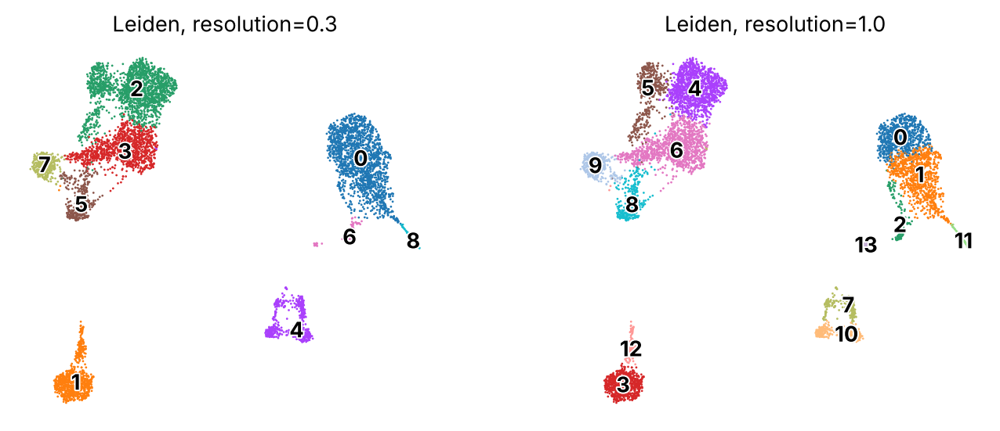

In [10]:
sc.pp.neighbors(pbmc, n_neighbors=15, n_pcs=30, random_state=42)
sc.tl.umap(pbmc, min_dist=0.3, random_state=42)

RESOLUTIONS = (0.3, 1.0)
for res in RESOLUTIONS:
    sc.tl.leiden(pbmc, resolution=res, key_added=f"leiden_{res}",
                 flavor="igraph", n_iterations=2, directed=False, random_state=42)

sc.pl.umap(pbmc, color=[f"leiden_{r}" for r in RESOLUTIONS], ncols=2,
           legend_loc="on data", legend_fontoutline=2, size=8,
           title=[f"Leiden, resolution={r}" for r in RESOLUTIONS])

In [11]:
sizes = pd.concat(
    {f"leiden_{r}": pbmc.obs[f"leiden_{r}"].value_counts().sort_index() for r in RESOLUTIONS},
    axis=1,
).fillna(0).astype(int)
sizes.index = sizes.index.astype(int)
display(sizes.sort_index().T)
print({f"leiden_{r}": pbmc.obs[f"leiden_{r}"].nunique() for r in RESOLUTIONS})

# Как кластеры низкого разрешения распадаются при высоком
ct = pd.crosstab(pbmc.obs["leiden_0.3"], pbmc.obs["leiden_1.0"],
                 rownames=["leiden_0.3"], colnames=["leiden_1.0"])
display(ct)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
leiden_0.3,1636,859,1805,1086,511,366,99,365,81,0,0,0,0,0
leiden_1.0,697,893,119,716,1258,495,1130,204,348,391,307,81,143,26


{'leiden_0.3': 9, 'leiden_1.0': 14}


leiden_1.0,0,1,2,3,4,5,6,7,8,9,10,11,12,13
leiden_0.3,,,,,,,,,,,,,,
0,697,893,46,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,716,0,0,0,0,0,0,0,0,143,0
2,0,0,0,0,1258,494,50,0,3,0,0,0,0,0
3,0,0,0,0,0,1,1080,0,4,1,0,0,0,0
4,0,0,0,0,0,0,0,204,0,0,307,0,0,0
5,0,0,0,0,0,0,0,0,341,25,0,0,0,0
6,0,0,73,0,0,0,0,0,0,0,0,0,0,26
7,0,0,0,0,0,0,0,0,0,365,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,81,0,0


**Что получилось.** При `resolution=0.3` — 9 кластеров, при `1.0` — 14. Таблица сопряжённости показывает, что кластеры почти строго вложены друг в друга, т.е. повышение разрешения в основном **дробит** крупные группы, а не перетасовывает клетки:

| Leiden 0.3 | → Leiden 1.0 | Что разделилось |
|---|---|---|
| 0 (1636) | 0 + 1 (+ 46 кл. в 2) | два состояния CD14⁺ моноцитов; часть cDC2 при низком разрешении «прилипала» к моноцитам |
| 1 (859) | 3 + 12 | две популяции NK: CD16^high и NKG2A⁺/CD56^bright-подобные |
| 2 (1805) | 4 + 5 | наивные CD4 и наивные CD8 T |
| 4 (511) | 7 + 10 | memory B (IgG) и наивные B (IgD/IgM) |
| 6 (99) | 2 (73) + 13 | cDC2 и pDC — при 0.3 все DC в одной группе |
| 5 (366) | 8 (+25 в 9) | эффекторные CD8 почти без изменений |
| 3, 7, 8 | 6, 9, 11 | не делятся |

**Ответы на вопросы.**

- *Как `resolution` влияет на число кластеров?* Resolution — вес «штрафа» в функции модулярности: чем он больше, тем выгоднее разбивать граф на более мелкие плотные сообщества, поэтому кластеров становится больше (9 → 14), а их средний размер меньше.
- *Какие кластеры разделились?* См. таблицу: биологически осмысленно разделились CD4/CD8, наивные/memory B, две группы NK, cDC2/pDC.
- *Обязательно ли кластер = тип клеток?* Нет. Кластер — это плотная область kNN-графа, а не биологическая категория. Пример «лишнего» дробления — кластеры 0 и 1 при 1.0: оба CD14⁺ моноциты, различаются уровнем `S100A8/9/12`, `VCAN` vs `HLA-DR`, `CST3`, `LGALS2`, т.е. это скорее **состояния** одного типа. Пример «недостаточного» дробления — кластер 6 (Memory CD4 T), который на самом деле содержит Treg и несколько субпопуляций памяти (задание 6).

## Задание 4. Ручная аннотация

Работаем с `leiden_1.0`: оно разделяет популяции, которые при 0.3 слиты (наивные CD4/CD8, наивные/memory B, CD56^bright/CD56^dim NK), а лишнее дробление всегда можно объединить на этапе аннотации.

Маркеры ищем так же, как в семинаре: Wilcoxon «кластер против остальных», все гены, лог-нормализованная `.X`, поправка Benjamini–Hochberg.

In [12]:
CLUSTER_KEY = "leiden_1.0"

sc.tl.rank_genes_groups(pbmc, groupby=CLUSTER_KEY, method="wilcoxon", reference="rest",
                        use_raw=False, tie_correct=True, corr_method="benjamini-hochberg",
                        pts=True, key_added="wilcoxon_hw")

# Для каждого кластера: топ-8 генов с p_adj < 0.05, log2FC > 1
# и с большой разницей доли экспрессирующих клеток (кластер vs остальные)
top_rows = []
for cl in pbmc.obs[CLUSTER_KEY].cat.categories:
    df = sc.get.rank_genes_groups_df(pbmc, group=cl, key="wilcoxon_hw")
    df = df[(df["pvals_adj"] < 0.05) & (df["logfoldchanges"] > 1)]
    df = df.head(8)
    top_rows.append({
        "cluster": cl,
        "n_cells": int((pbmc.obs[CLUSTER_KEY] == cl).sum()),
        "top_genes (log2FC; доля в кластере / в остальных)": ", ".join(
            f"{g} ({fc:.1f}; {p:.0%}/{pr:.0%})"
            for g, fc, p, pr in zip(df["names"], df["logfoldchanges"], df["pct_nz_group"], df["pct_nz_reference"])
        ),
    })
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(top_rows).set_index("cluster"))

,n_cells,top_genes (log2FC; доля в кластере / в остальных)
cluster,,
0,697,"S100A12 (5.9; 99%/15%), S100A8 (7.7; 100%/21%), S100A9 (7.9; 100%/23%), VCAN (5.1; 99%/17%), CYP1B1 (5.0; 67%/5%), FCN1 (5.0; 100%/18%), CD14 (4.7; 99%/16%), MNDA (4.7; 100%/19%)"
1,893,"LGALS2 (5.5; 89%/6%), CPVL (4.5; 88%/10%), SERPINA1 (4.4; 98%/15%), MS4A6A (4.4; 96%/14%), CD14 (4.6; 98%/14%), CFD (4.2; 95%/14%), CST3 (5.3; 100%/19%), FGL2 (4.1; 96%/17%)"
2,119,"FCER1A (9.5; 66%/0%), ENHO (7.8; 49%/0%), CLEC10A (6.5; 77%/3%), PKIB (7.2; 38%/0%), CD1C (5.8; 60%/2%), PLD4 (4.4; 60%/3%), CD1E (6.8; 22%/0%), FLT3 (4.3; 61%/4%)"
3,716,"FGFBP2 (7.1; 98%/5%), GZMB (6.6; 94%/4%), GZMH (6.7; 97%/6%), KLRF1 (6.1; 92%/6%), GNLY (8.2; 100%/13%), KLRD1 (5.8; 97%/9%), FCGR3A (5.7; 92%/8%), TRDC (5.3; 82%/5%)"
4,1258,"RPL30 (1.1; 100%/100%), RPS3A (1.1; 100%/100%), RPL32 (1.1; 100%/100%), LEF1 (3.4; 72%/15%), RPS13 (1.0; 100%/100%), RPS27A (1.1; 100%/100%), RPS15A (1.0; 100%/100%), RPS27 (1.1; 100%/100%)"
5,495,"LINC02446 (6.3; 61%/2%), CD8B (5.1; 81%/7%), CD8A (3.5; 61%/8%), NELL2 (3.5; 48%/6%), LEF1 (2.3; 70%/22%), RPS5 (1.1; 100%/97%), EEF1B2 (1.2; 100%/93%), LDLRAP1 (2.1; 60%/20%)"
6,1130,"TNFRSF4 (4.8; 31%/1%), AQP3 (2.8; 59%/13%), TRAC (2.6; 95%/42%), LTB (2.4; 95%/49%), IL7R (2.6; 87%/37%), IL32 (2.3; 98%/53%), LDHB (1.7; 95%/66%), CD3D (2.0; 88%/38%)"
7,204,"IGHG1 (7.4; 52%/1%), BANK1 (5.9; 89%/4%), MS4A1 (6.4; 93%/6%), CD79A (6.3; 97%/6%), TNFRSF13B (7.9; 33%/0%), IGHG3 (6.4; 54%/2%), BLK (5.5; 54%/2%), IGHG4 (6.0; 53%/2%)"
8,348,"CD8A (4.3; 68%/9%), CD8B (4.1; 69%/9%), TRGC2 (3.9; 69%/10%), CCL5 (4.7; 99%/26%), GZMH (3.8; 71%/13%), NKG7 (4.6; 98%/26%), GZMA (3.7; 95%/24%), CST7 (3.5; 91%/23%)"


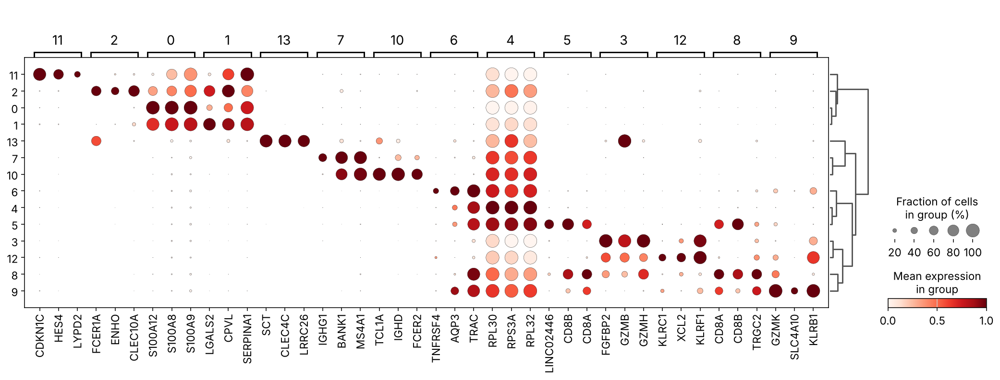

In [13]:
sc.pl.rank_genes_groups_dotplot(pbmc, key="wilcoxon_hw", groupby=CLUSTER_KEY, n_genes=3,
                                use_raw=False, standard_scale="var")

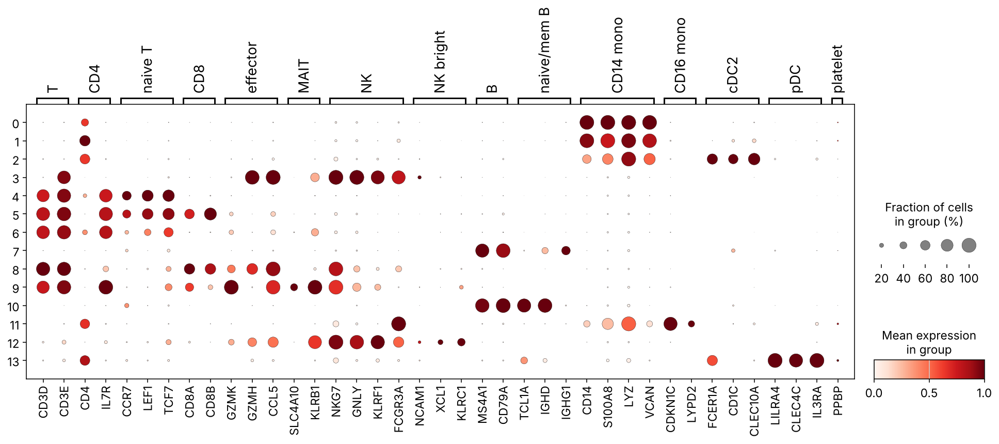

In [14]:
MARKERS_HW = {
    "T":            ["CD3D", "CD3E"],
    "CD4":          ["CD4", "IL7R"],
    "naive T":      ["CCR7", "LEF1", "TCF7"],
    "CD8":          ["CD8A", "CD8B"],
    "effector":     ["GZMK", "GZMH", "CCL5"],
    "MAIT":         ["SLC4A10", "KLRB1"],
    "NK":           ["NKG7", "GNLY", "KLRF1", "FCGR3A"],
    "NK bright":    ["NCAM1", "XCL1", "KLRC1"],
    "B":            ["MS4A1", "CD79A"],
    "naive/mem B":  ["TCL1A", "IGHD", "IGHG1"],
    "CD14 mono":    ["CD14", "S100A8", "LYZ", "VCAN"],
    "CD16 mono":    ["CDKN1C", "LYPD2"],
    "cDC2":         ["FCER1A", "CD1C", "CLEC10A"],
    "pDC":          ["LILRA4", "CLEC4C", "IL3RA"],
    "platelet":     ["PPBP"],
}
markers_hw = {k: [g for g in v if g in pbmc.var_names] for k, v in MARKERS_HW.items()}
markers_hw = {k: v for k, v in markers_hw.items() if v}

sc.pl.dotplot(pbmc, markers_hw, groupby=CLUSTER_KEY, standard_scale="var",
              use_raw=False, figsize=(17, 5))

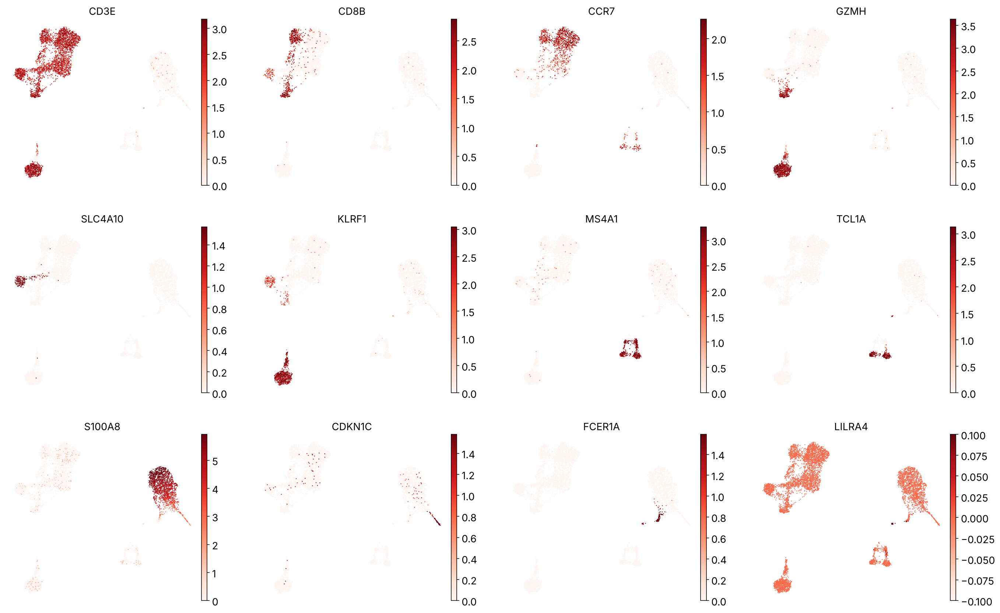

In [15]:
sc.pl.umap(pbmc, color=["CD3E", "CD8B", "CCR7", "GZMH", "SLC4A10", "KLRF1",
                        "MS4A1", "TCL1A", "S100A8", "CDKN1C", "FCER1A", "LILRA4"],
           ncols=4, use_raw=False, size=6, cmap="Reds", vmax="p99")

### Независимая проверка по белкам (CITE-seq)

Счёты антител нормализуем CLR (centered log-ratio) по клетке — стандартная нормализация ADT: $\mathrm{CLR}(x_{cp}) = \log(1+x_{cp}) - \frac{1}{P}\sum_{p'}\log(1+x_{cp'})$. Белок часто детектируется надёжнее мРНК (например, `CD4` и `NCAM1`/CD56 плохо ловятся в РНК, но хорошо — антителом).

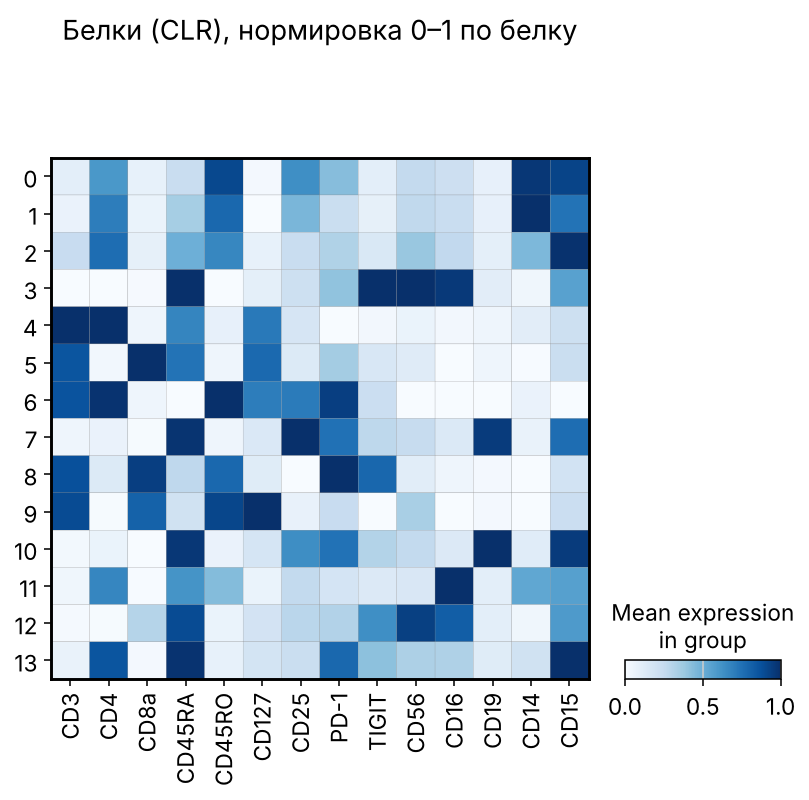

In [16]:
adt_log = np.log1p(pbmc.obsm["adt"])
pbmc.obsm["adt_clr"] = adt_log.sub(adt_log.mean(axis=1), axis=0)

adt_view = ad.AnnData(pbmc.obsm["adt_clr"].to_numpy(dtype=np.float32),
                      obs=pbmc.obs[[CLUSTER_KEY]].copy(),
                      var=pd.DataFrame(index=pbmc.obsm["adt_clr"].columns))
adt_order = ["CD3", "CD4", "CD8a", "CD45RA", "CD45RO", "CD127", "CD25",
             "PD-1", "TIGIT", "CD56", "CD16", "CD19", "CD14", "CD15"]
sc.pl.matrixplot(adt_view, adt_order, groupby=CLUSTER_KEY, standard_scale="var",
                 cmap="Blues", title="Белки (CLR), нормировка 0–1 по белку")

### Итоговая таблица ручной аннотации (`leiden_1.0`)

| Кластер | Клеток | Тип клеток | Маркерные гены (РНК) | Обоснование, включая белки |
|---|---|---|---|---|
| 0 | 697 | CD14⁺ Monocyte | `CD14`, `S100A8/9/12`, `VCAN`, `FCN1`, `LYZ` | классические моноциты; белок CD14 высокий, CD16 низкий |
| 1 | 893 | CD14⁺ Monocyte | `CD14`, `LGALS2`, `CPVL`, `CST3`, `MS4A6A` | тоже CD14^high по белку; отличие от 0 — выше MHC-II (`HLA-DRA`, `CD74`), ниже `S100A12`/`VCAN`. Это состояние, а не отдельный тип, поэтому метка общая |
| 2 | 119 | cDC2 | `FCER1A`, `CD1C`, `CLEC10A`, `FLT3` | классический набор cDC2; максимальный `HLA-DRA`; CD14 по белку низкий |
| 3 | 716 | NK CD56dim | `GNLY`, `GZMB`, `GZMH`, `KLRF1`, `FGFBP2`, `FCGR3A` | CD3 по белку отрицателен, CD16 и CD56 высокие. `TRDC` в РНК не означает γδ T: у NK есть «зародышевые» транскрипты TRDC, а CD3 нет |
| 4 | 1258 | Naive CD4 T | `LEF1`, `CCR7`, `TCF7`, рибосомные `RPL/RPS` | белки CD3⁺ CD4⁺ CD8a⁻, CD45RA^high, CD45RO^low, CD127⁺ |
| 5 | 495 | Naive CD8 T | `CD8A`, `CD8B`, `LEF1`, `NELL2`, `LINC02446` | CD3⁺ CD8a⁺ CD4⁻, CD45RA^high |
| 6 | 1130 | Memory CD4 T | `IL7R`, `LTB`, `AQP3`, `TNFRSF4`, `IL32` | CD4⁺, CD45RO^high, CD45RA^low → память |
| 7 | 204 | Memory B | `MS4A1`, `CD79A`, `IGHG1/3/4`, `TNFRSF13B` (TACI), `BANK1` | переключённые изотипы IgG → B памяти; CD19⁺ |
| 8 | 348 | Effector memory CD8 T | `CD8A/B`, `CCL5`, `GZMH`, `NKG7`, `GZMA`, `KLRG1` | CD3⁺ CD8a⁺, CD45RO повышен; `TRDC` лишь у 5 % клеток → в основном αβ T |
| 9 | 391 | MAIT | `SLC4A10`, `KLRB1` (CD161, 98 % клеток), `GZMK`, `NCR3` | `SLC4A10` + `KLRB1` — характерная пара MAIT; CD3⁺, CD127^high |
| 10 | 307 | Naive B | `TCL1A`, `IGHD`, `IGHM`, `FCER2` (CD23) | IgD⁺ наивные B; CD19⁺ CD45RA^high |
| 11 | 81 | CD16⁺ Monocyte | `CDKN1C`, `HES4`, `LYPD2`, `C1QA`, `FCGR3A` | неклассические моноциты: CD16 по белку максимальный, CD14 низкий |
| 12 | 143 | NK CD56bright-like | `KLRC1` (NKG2A), `XCL1/2`, `IL2RB`, `KLRF1` | CD3⁻, CD16 ниже, чем в кластере 3, цитотоксических генов меньше. Белок CD56 не выше, чем у кластера 3, поэтому название осторожное: «‑like» |
| 13 | 26 | pDC | `LILRA4`, `CLEC4C`, `IL3RA`, `LRRC26` | канонические маркеры pDC |

Тромбоцитов (`PPBP`, `PF4`) отдельным кластером нет — `PPBP` детектируется лишь в 63 клетках из 6808, вероятно, как фоновая РНК.

,n_cells
manual_cell_type,
CD14+ Monocyte,1590
Naive CD4 T,1258
Memory CD4 T,1130
NK CD56dim,716
Naive CD8 T,495
MAIT,391
Effector memory CD8 T,348
Naive B,307
Memory B,204


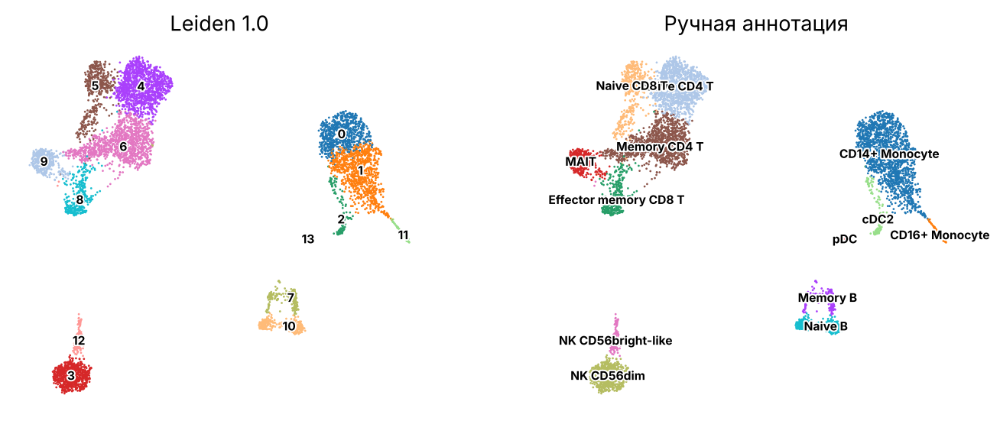

In [17]:
manual_hw = {
    "0":  "CD14+ Monocyte",
    "1":  "CD14+ Monocyte",
    "2":  "cDC2",
    "3":  "NK CD56dim",
    "4":  "Naive CD4 T",
    "5":  "Naive CD8 T",
    "6":  "Memory CD4 T",
    "7":  "Memory B",
    "8":  "Effector memory CD8 T",
    "9":  "MAIT",
    "10": "Naive B",
    "11": "CD16+ Monocyte",
    "12": "NK CD56bright-like",
    "13": "pDC",
}
missing = set(pbmc.obs[CLUSTER_KEY].cat.categories) - set(manual_hw)
assert not missing, f"Нет аннотации для кластеров {missing}"

pbmc.obs["manual_cell_type"] = pd.Categorical(pbmc.obs[CLUSTER_KEY].astype(str).map(manual_hw))
display(pbmc.obs["manual_cell_type"].value_counts().to_frame("n_cells"))

sc.pl.umap(pbmc, color=[CLUSTER_KEY, "manual_cell_type"], ncols=2, size=8,
           legend_loc="on data", legend_fontsize=8, legend_fontoutline=2,
           title=["Leiden 1.0", "Ручная аннотация"])

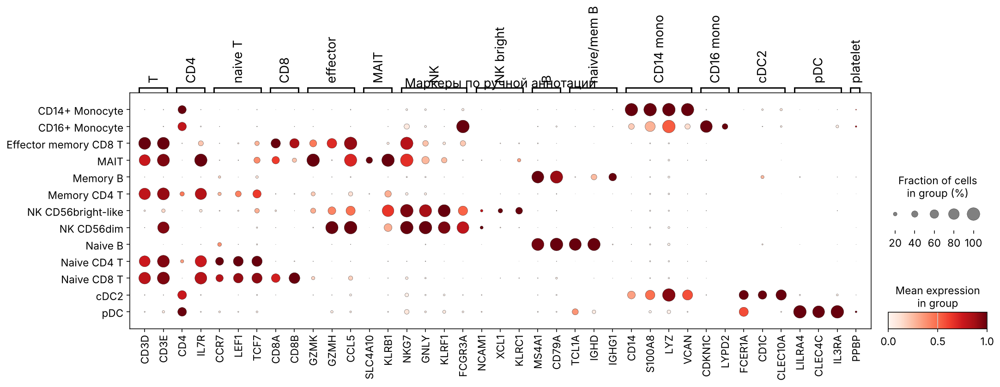

In [18]:
sc.pl.dotplot(pbmc, markers_hw, groupby="manual_cell_type", standard_scale="var",
              use_raw=False, figsize=(17, 4.8), title="Маркеры по ручной аннотации")

## Задание 5. Автоматическая аннотация: SingleR + референс Monaco

CellTypist мы уже применяли в семинаре, поэтому здесь берём другой инструмент — **SingleR** (Aran et al., *Nat. Immunol.* 2019), его Python-реализацию из BiocPy (`singler`).

**Как работает SingleR.** Для каждой метки референса находятся гены-маркеры (попарные различия между метками). Для каждой клетки считается корреляция Спирмена её профиля с профилями каждой метки референса по этим генам; метка с максимальной корреляцией — предсказание. Затем «fine-tuning»: итеративно оставляются только лучшие метки и маркеры, различающие именно их. Метод основан на **рангах**, поэтому ему неважна нормализация, и он одинаково работает со scRNA-seq и с bulk-референсом.

**Почему Monaco.** Это bulk RNA-seq 29 иммунных популяций, отсортированных из PBMC здоровых доноров проточной цитометрией (4 донора на тип), т.е. ткань и вид совпадают с нашими данными. У референса два уровня меток: `main` (10 крупных типов) и `fine` (29 подтипов). В файлах релиза хранятся не сами экспрессии, а **ранги** генов в каждом образце — этого SingleR достаточно.

In [19]:
import singler

MONACO_URL = "https://github.com/kanaverse/singlepp-references/releases/download/2023-04-28/"
monaco_files = ["matrix", "genes_symbol", "labels_main", "label_names_main",
                "labels_fine", "label_names_fine"]
mp = {f: download(MONACO_URL + f"MonacoImmune_{f}.csv.gz", HW_DIR / f"MonacoImmune_{f}.csv.gz")
      for f in monaco_files}

def read_col(path):
    return pd.read_csv(path, header=None, keep_default_na=False)[0].to_numpy()

ref_mat = pd.read_csv(mp["matrix"], header=None).to_numpy(dtype=np.float64).T   # гены × образцы
ref_genes = read_col(mp["genes_symbol"])
ref_main = read_col(mp["label_names_main"])[read_col(mp["labels_main"]).astype(int)]
ref_fine = read_col(mp["label_names_fine"])[read_col(mp["labels_fine"]).astype(int)]

print("Референс:", ref_mat.shape[1], "образцов ×", ref_mat.shape[0], "генов;",
      len(set(ref_main)), "main-меток,", len(set(ref_fine)), "fine-меток")
print("Общих генов с нашими данными:", len(set(ref_genes) & set(pbmc.var_names)))

Референс: 114 образцов × 46077 генов; 10 main-меток, 29 fine-меток
Общих генов с нашими данными: 14314


In [20]:
test_mat = pbmc.X.T.tocsc()          # SingleR ждёт гены × клетки
test_genes = pbmc.var_names.to_numpy()

for level, labels in [("main", ref_main), ("fine", ref_fine)]:
    res = singler.annotate_single(
        test_data=test_mat, test_features=test_genes,
        ref_data=ref_mat, ref_labels=labels, ref_features=ref_genes,
    )
    pbmc.obs[f"singler_{level}"] = pd.Categorical(np.asarray(res.get_column("best")))
    pbmc.obs[f"singler_{level}_delta"] = np.asarray(res.get_column("delta"), dtype=float)

display(pbmc.obs["singler_main"].value_counts().to_frame("n_cells"))

,n_cells
singler_main,
CD4+ T cells,1711
Monocytes,1519
T cells,1105
CD8+ T cells,933
NK cells,699
B cells,524
Dendritic cells,287
Neutrophils,17
Progenitors,13


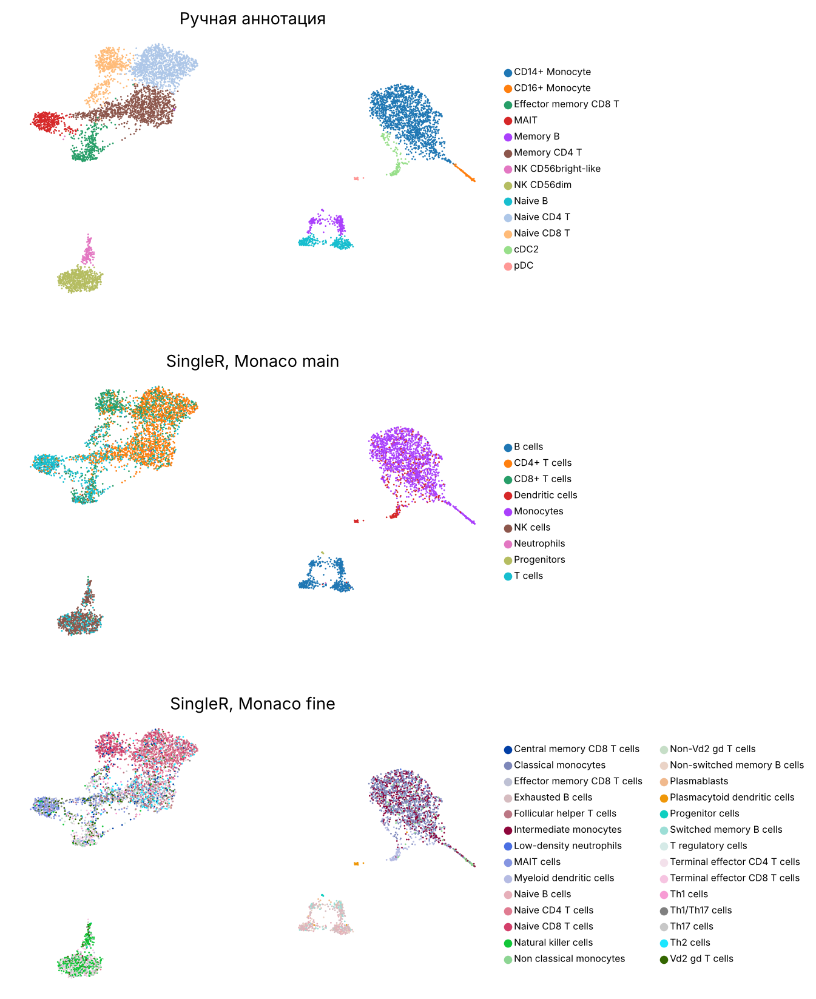

In [21]:
sc.pl.umap(pbmc, color=["manual_cell_type", "singler_main", "singler_fine"], ncols=1,
           size=8, legend_fontsize=8, wspace=0.6,
           title=["Ручная аннотация", "SingleR, Monaco main", "SingleR, Monaco fine"])

SingleR main,B cells,CD4+ T cells,CD8+ T cells,Dendritic cells,Monocytes,NK cells,Neutrophils,Progenitors,T cells
Ручная,,,,,,,,,
CD14+ Monocyte,3,0,0,174,1396,0,16,1,0
CD16+ Monocyte,0,0,0,1,80,0,0,0,0
Effector memory CD8 T,0,35,130,0,0,36,0,0,147
MAIT,0,48,26,0,0,18,0,0,299
Memory B,197,0,0,1,0,0,0,6,0
Memory CD4 T,11,732,137,0,1,8,0,2,239
NK CD56bright-like,1,0,4,0,0,106,0,0,32
NK CD56dim,1,0,22,0,0,510,0,1,182
Naive B,300,0,0,4,1,0,1,1,0


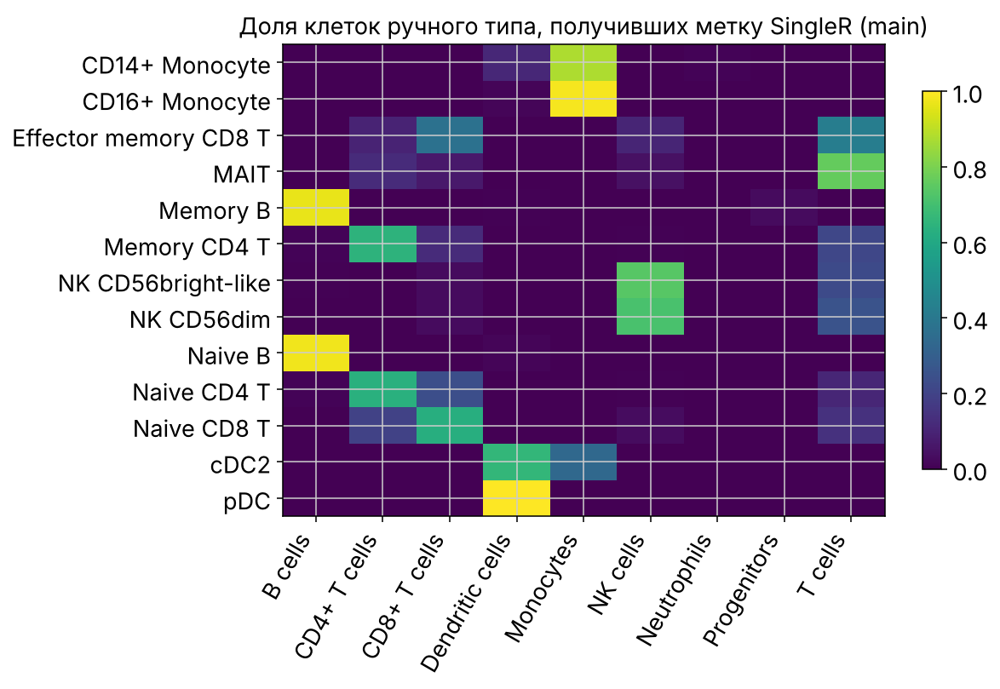

In [22]:
# Сопоставление ручной аннотации и SingleR (main) — доли по строкам
ct_main = pd.crosstab(pbmc.obs["manual_cell_type"], pbmc.obs["singler_main"],
                      rownames=["Ручная"], colnames=["SingleR main"])
display(ct_main)

fig, ax = plt.subplots(figsize=(9, 6))
frac = ct_main.div(ct_main.sum(axis=1), axis=0)
im = ax.imshow(frac.to_numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(frac.shape[1]), frac.columns, rotation=60, ha="right")
ax.set_yticks(range(frac.shape[0]), frac.index)
ax.set_title("Доля клеток ручного типа, получивших метку SingleR (main)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

In [23]:
# Согласие на уровне кластера: метка SingleR (fine), которую получило большинство клеток кластера
def majority(s):
    vc = s.value_counts()
    return pd.Series({"majority_label": vc.index[0], "share": vc.iloc[0] / vc.sum(),
                      "2nd_label": vc.index[1] if len(vc) > 1 else "",
                      "2nd_share": vc.iloc[1] / vc.sum() if len(vc) > 1 else 0})

cluster_vote = (pbmc.obs.groupby(CLUSTER_KEY, observed=True)["singler_fine"]
                .apply(majority).unstack())
cluster_vote.insert(0, "manual", [manual_hw[c] for c in cluster_vote.index])
cluster_vote["main_majority"] = (pbmc.obs.groupby(CLUSTER_KEY, observed=True)["singler_main"]
                                 .agg(lambda s: s.value_counts().index[0]))
display(cluster_vote.style.format({"share": "{:.0%}", "2nd_share": "{:.0%}"}))

,manual,majority_label,share,2nd_label,2nd_share,main_majority
leiden_1.0,,,,,,
0,CD14+ Monocyte,Classical monocytes,59%,Intermediate monocytes,32%,Monocytes
1,CD14+ Monocyte,Classical monocytes,51%,Intermediate monocytes,33%,Monocytes
2,cDC2,Myeloid dendritic cells,67%,Classical monocytes,18%,Dendritic cells
3,NK CD56dim,Natural killer cells,43%,Terminal effector CD8 T cells,26%,NK cells
4,Naive CD4 T,Naive CD4 T cells,33%,Naive CD8 T cells,26%,CD4+ T cells
5,Naive CD8 T,Naive CD8 T cells,49%,Naive CD4 T cells,12%,CD8+ T cells
6,Memory CD4 T,Follicular helper T cells,14%,Th2 cells,12%,CD4+ T cells
7,Memory B,Exhausted B cells,51%,Switched memory B cells,23%,B cells
8,Effector memory CD8 T,Terminal effector CD8 T cells,16%,Non-Vd2 gd T cells,15%,T cells


In [24]:
# Грубое согласие по крупным линиям
to_lineage_manual = {
    "Naive CD4 T": "CD4+ T cells", "Memory CD4 T": "CD4+ T cells",
    "Naive CD8 T": "CD8+ T cells", "Effector memory CD8 T": "CD8+ T cells",
    "MAIT": "T cells",
    "NK CD56dim": "NK cells", "NK CD56bright-like": "NK cells",
    "Naive B": "B cells", "Memory B": "B cells",
    "CD14+ Monocyte": "Monocytes", "CD16+ Monocyte": "Monocytes",
    "cDC2": "Dendritic cells", "pDC": "Dendritic cells",
}
lin_manual = pbmc.obs["manual_cell_type"].astype(str).map(to_lineage_manual)
lin_auto = pbmc.obs["singler_main"].astype(str)
agree = (lin_manual == lin_auto)
# MAIT и Т-клетки без уточнения: SingleR main кладёт их в CD4/CD8/T cells — считаем любую T-метку совпадением
is_t = lin_manual.eq("T cells") & lin_auto.isin(["T cells", "CD4+ T cells", "CD8+ T cells"])
agree = agree | is_t
print(f"Согласие ручной аннотации и SingleR main на уровне линий: {agree.mean():.1%}")
display(agree.groupby(pbmc.obs["manual_cell_type"], observed=True).mean()
        .sort_values().to_frame("доля совпадений").style.format("{:.0%}"))

Согласие ручной аннотации и SingleR main на уровне линий: 74.0%


,доля совпадений
manual_cell_type,
Effector memory CD8 T,37%
Naive CD8 T,63%
Naive CD4 T,64%
Memory CD4 T,65%
cDC2,66%
NK CD56dim,71%
NK CD56bright-like,74%
CD14+ Monocyte,88%
MAIT,95%


### Кто прав в спорных случаях? Арбитраж по белкам

У нас есть независимый «судья» — поверхностные белки. Посмотрим на клетки трёх кластеров с наибольшими расхождениями, разбитые по метке SingleR.

In [25]:
adt = pbmc.obsm["adt_clr"]
checks = [("4", "Naive CD4 T", ["CD3", "CD4", "CD8a"]),
          ("3", "NK CD56dim", ["CD3", "CD56", "CD16"]),
          ("8", "Effector memory CD8 T", ["CD3", "CD4", "CD8a"])]
for cl, name, prots in checks:
    m = pbmc.obs[CLUSTER_KEY] == cl
    tab = adt.loc[m, prots].groupby(pbmc.obs.loc[m, "singler_main"], observed=True).mean()
    tab["n_cells"] = pbmc.obs.loc[m, "singler_main"].value_counts()
    tab = tab[tab["n_cells"] >= 20]
    print(f"Кластер {cl} (ручная метка: {name}) — средний CLR белков по меткам SingleR")
    display(tab.round(2))

# Детекция мРНК ключевых генов (доля клеток с UMI > 0)
det = (pbmc[:, ["CD4", "CD8A", "CD8B", "TRDC", "CD3E"]].to_df() > 0)
display(det.groupby(pbmc.obs["manual_cell_type"], observed=True).mean()
        .loc[["Naive CD4 T", "Naive CD8 T", "NK CD56dim", "Effector memory CD8 T"]]
        .style.format("{:.0%}"))

Кластер 4 (ручная метка: Naive CD4 T) — средний CLR белков по меткам SingleR


,CD3,CD4,CD8a,n_cells
singler_main,,,,
CD4+ T cells,3.66,3.55,-0.84,799
CD8+ T cells,3.62,3.24,-0.61,304
T cells,3.61,3.49,-0.78,135


Кластер 3 (ручная метка: NK CD56dim) — средний CLR белков по меткам SingleR


,CD3,CD56,CD16,n_cells
singler_main,,,,
CD8+ T cells,-0.63,2.07,2.85,22
NK cells,-0.84,2.03,3.00,510
T cells,-0.87,2.02,3.02,182


Кластер 8 (ручная метка: Effector memory CD8 T) — средний CLR белков по меткам SingleR


,CD3,CD4,CD8a,n_cells
singler_main,,,,
CD4+ T cells,3.03,-0.02,3.01,35
CD8+ T cells,3.08,-0.40,3.53,130
NK cells,3.04,-0.84,3.88,36
T cells,3.15,-0.51,3.37,147


index,CD4,CD8A,CD8B,TRDC,CD3E
manual_cell_type,,,,,
Naive CD4 T,17%,1%,3%,3%,93%
Naive CD8 T,1%,61%,81%,12%,95%
NK CD56dim,0%,1%,0%,82%,88%
Effector memory CD8 T,2%,68%,69%,5%,94%


**Ответы на вопросы задания 5.**

*Где аннотации совпали.* На уровне крупных линий — 74 % клеток. Почти полное совпадение у B-клеток (97–98 %), неклассических моноцитов (99 %), pDC (100 %), MAIT (95 %; на уровне fine большинство клеток кластера 9 получили именно метку `MAIT cells`), классических моноцитов (88 %). Большинство кластеров совпадают и при голосовании по кластеру (fine): Classical monocytes, Myeloid DC, NK, Naive CD4, Naive CD8, MAIT, Non classical monocytes, pDC.

*Где расхождения и с чем они связаны.*

1. **Naive CD4 T → «CD8⁺ T cells»** (304 клетки). Белки однозначно говорят, что это CD4: CD4 CLR ≈ 3.2, CD8a ≈ −0.6. Причина — мРНК `CD4` детектируется лишь у ~17 % клеток, а bulk-профили наивных CD4 и CD8 в Monaco различаются немногими генами, которые в разреженных данных 10x часто выпадают (dropout).
2. **NK CD56dim и Effector memory CD8 → «T cells»** (182 и 147 клеток). В Monaco метка main `T cells` — это γδ T и MAIT, у которых общая с NK и эффекторными CD8 цитотоксическая программа (`GZMB`, `GNLY`, `NKG7`). Белок CD3 у «NK» отрицателен (хотя мРНК `CD3E` детектируется у 88 % этих клеток: NK транскрибируют CD3ε, но не собирают поверхностный комплекс CD3), а у кластера 8 есть и CD3, и CD8a — ручная аннотация верна.
3. **CD14⁺ моноциты → «Dendritic cells»** (174) и обратно cDC2 → «Monocytes» (40). Это в основном кластер 1 с высоким MHC-II: моноциты и cDC2 образуют непрерывный спектр, и для части клеток граница действительно размыта.
4. **«Exhausted B cells»** у большинства B-клеток. Это метка атипичных (CD27⁻IgD⁻) B из Monaco; на уровне отдельных клеток fine-метки B-подтипов ненадёжны, но на уровне main (B cells) совпадение почти полное.
5. **Memory CD4** получает целый «веер» fine-меток (Tfh 14 %, Th2 12 %, Th17, Th1/Th17, Treg…). Ни одна не доминирует — это сигнал неоднородности кластера, который мы разбираем в задании 6.

Общие причины: референс — bulk RNA-seq отсортированных клеток (другая технология, глубина и «шум»), низкое покрытие 3′ scRNA-seq, а также то, что многие подтипы T и NK образуют континуум, а не дискретные классы.

*Какая аннотация обоснованнее.* Для крупных типов — **ручная**: во всех трёх главных спорных случаях её подтверждают белки CITE-seq. SingleR полезен как независимая проверка и подсказка для тонких подтипов (MAIT, pDC, неклассические моноциты, гетерогенность памяти CD4), но его поклеточные fine-метки нельзя принимать без проверки маркерами.

## Задание 6. Субкластеризация: Memory CD4 T (кластер 6)

**Почему этот кластер.** «Memory CD4 T» по определению неоднороден: в нём смешаны центральная и эффекторная память, функциональные хелперы (Th1, Th17, Th2…) и регуляторные T-клетки (Treg). Treg составляют 5–10 % CD4 в крови, но в общей кластеризации отдельного кластера не образовали. SingleR (fine) внутри кластера 6 тоже раздаёт сразу несколько меток (Treg, Th1/Th17, Th2, Tfh). Белки CD25 (IL2RA) и CD127 (IL7R) позволят проверить выделение Treg (классический фенотип CD25^high CD127^low).

Повторяем пайплайн **заново** на подмножестве: HVG пересчитываются по сырым counts только этих клеток — так находятся гены, которые различаются **внутри** популяции, а не между T-клетками и моноцитами.

Клеток в подмножестве: 1130


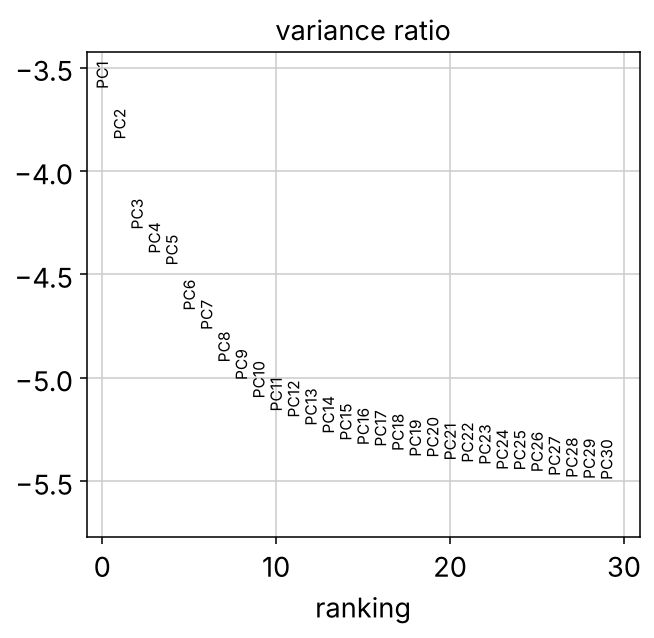

In [26]:
SUB_CLUSTER = "6"
sub = pbmc[pbmc.obs[CLUSTER_KEY] == SUB_CLUSTER].copy()
print("Клеток в подмножестве:", sub.n_obs)

sub.X = sub.layers["counts"].copy()
sub.uns.pop("log1p", None)   # .X снова сырые counts — убираем пометку о логарифмировании
sc.pp.highly_variable_genes(sub, layer="counts", flavor="seurat_v3", n_top_genes=1500)
sc.pp.normalize_total(sub, target_sum=1e4)
sc.pp.log1p(sub)
sc.tl.pca(sub, n_comps=30, mask_var="highly_variable", random_state=42)
sc.pl.pca_variance_ratio(sub, n_pcs=30, log=True)

sub_leiden,0,1,2,3,4
n_cells,348,343,218,69,152


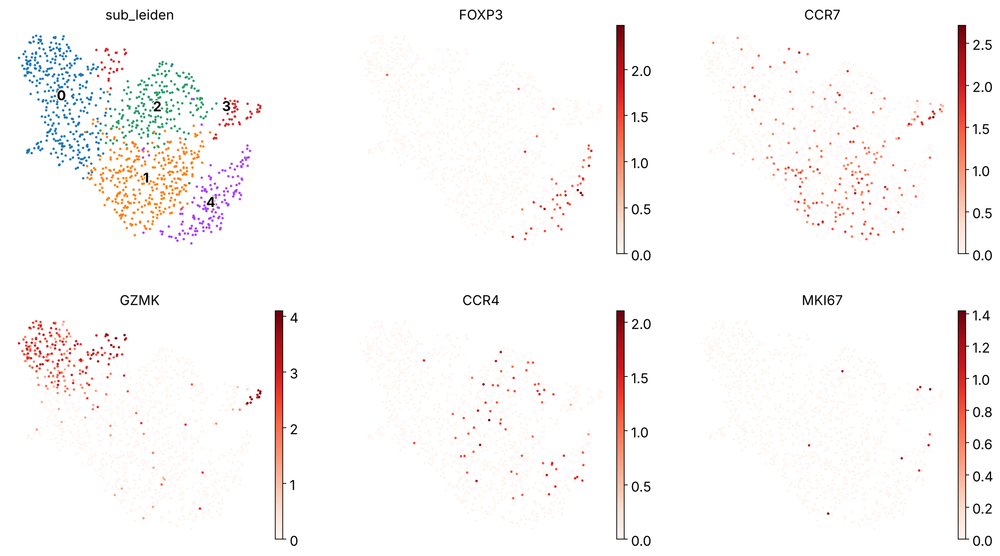

In [27]:
sc.pp.neighbors(sub, n_neighbors=15, n_pcs=15, random_state=42)
sc.tl.umap(sub, min_dist=0.3, random_state=42)
sc.tl.leiden(sub, resolution=0.5, key_added="sub_leiden",
             flavor="igraph", n_iterations=2, directed=False, random_state=42)

display(sub.obs["sub_leiden"].value_counts().sort_index().to_frame("n_cells").T)
sc.pl.umap(sub, color=["sub_leiden", "FOXP3", "CCR7", "GZMK", "CCR4", "MKI67"],
           ncols=3, size=25, use_raw=False, cmap="Reds", legend_loc="on data", legend_fontoutline=2)

,топ-15 маркеров субкластера
0,"GZMA, CCL5, IL7R, LYAR, GZMK, HOPX, CTSW, KLRB1, ID2, KLRG1, NKG7, MYBL1, DPP4, MATK, GNLY"
1,"PASK, TCF7, LINC00402, CCR7, LEF1, SELL, FYB1, ACTN1, TSHZ2, APBA2, SERINC5, IL6ST, MARCKSL1, TXK, AP3M2"
2,"VIM, C1ORF162, LGALS1, CLU, COTL1, CAPG, ANXA1, LPAR6, PLP2, S100A6, LMNA, S100A4, CCR10, CD99, AIRE"
3,"CD38, CHI3L2, TMSB4X, PCLAF, AC004585.1, GZMK, LRMP, FABP5, PACSIN1, SESTD1, PECAM1, PFN1, CDCA7, BIRC5, MIR4422HG"
4,"FOXP3, RTKN2, TIGIT, FCRL3, HACD1, PTGIR, FANK1, IKZF2, SELL, DUSP4, PMAIP1, AC133644.2, AC011997.1, IL32, HLA-DQA2"


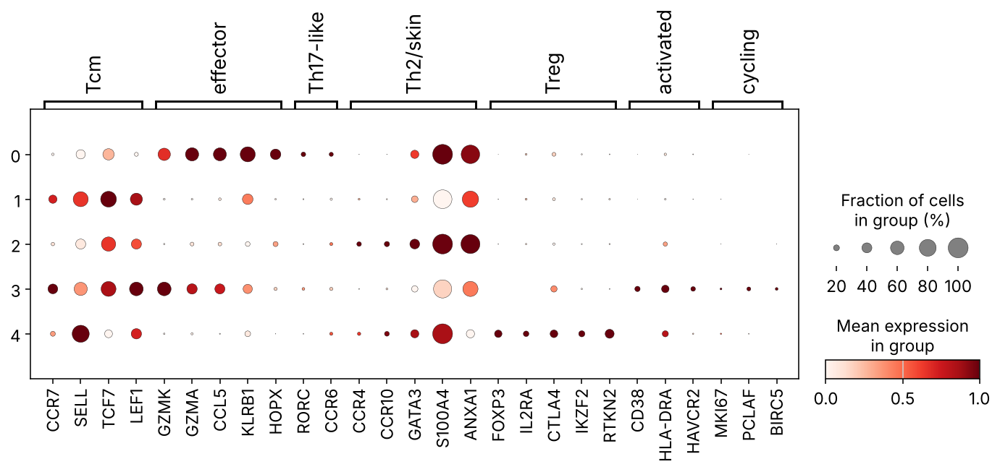

In [28]:
sc.tl.rank_genes_groups(sub, groupby="sub_leiden", method="wilcoxon", use_raw=False,
                        tie_correct=True, pts=True, key_added="wilcoxon_sub")
sub_top = {}
for cl in sub.obs["sub_leiden"].cat.categories:
    df = sc.get.rank_genes_groups_df(sub, group=cl, key="wilcoxon_sub")
    df = df[(df["pvals_adj"] < 0.05) & (df["logfoldchanges"] > 0.5)]
    sub_top[cl] = ", ".join(df["names"].head(15))
display(pd.Series(sub_top, name="топ-15 маркеров субкластера").to_frame())

SUB_MARKERS = {
    "Tcm":        ["CCR7", "SELL", "TCF7", "LEF1"],
    "effector":   ["GZMK", "GZMA", "CCL5", "KLRB1", "HOPX"],
    "Th17-like":  ["RORC", "CCR6"],
    "Th2/skin":   ["CCR4", "CCR10", "GATA3", "S100A4", "ANXA1"],
    "Treg":       ["FOXP3", "IL2RA", "CTLA4", "IKZF2", "RTKN2"],
    "activated":  ["CD38", "HLA-DRA", "HAVCR2"],
    "cycling":    ["MKI67", "PCLAF", "BIRC5"],
}
SUB_MARKERS = {k: [g for g in v if g in sub.var_names] for k, v in SUB_MARKERS.items()}
sc.pl.dotplot(sub, SUB_MARKERS, groupby="sub_leiden", standard_scale="var",
              use_raw=False, figsize=(12, 3.5))

In [29]:
sub_adt = sub.obsm["adt_clr"].groupby(sub.obs["sub_leiden"], observed=True).mean()
display(sub_adt[["CD4", "CD8a", "CD45RA", "CD45RO", "CD127", "CD25", "PD-1", "TIGIT"]]
        .style.background_gradient(cmap="Blues", axis=0).format("{:.2f}"))

display(pd.crosstab(sub.obs["sub_leiden"], sub.obs["singler_fine"])
        .loc[:, lambda d: d.sum() >= 15])

,CD4,CD8a,CD45RA,CD45RO,CD127,CD25,PD-1,TIGIT
sub_leiden,,,,,,,,
0,3.29,-0.56,-0.11,2.13,1.19,-0.65,-0.46,-2.23
1,3.54,-0.93,-0.10,2.23,0.39,-0.98,-0.52,-1.48
2,3.52,-0.72,-0.28,2.43,0.45,-0.59,-0.52,-1.85
3,3.01,-0.69,0.75,1.92,-0.90,-1.38,0.29,-1.22
4,3.33,-1.04,-0.40,2.20,-1.24,0.73,-0.41,-0.28


singler_fine,Central memory CD8 T cells,Effector memory CD8 T cells,Follicular helper T cells,MAIT cells,Naive CD4 T cells,Naive CD8 T cells,Non-Vd2 gd T cells,T regulatory cells,Terminal effector CD4 T cells,Terminal effector CD8 T cells,Th1 cells,Th1/Th17 cells,Th17 cells,Th2 cells,Vd2 gd T cells
sub_leiden,,,,,,,,,,,,,,,
0,17,4,24,82,4,1,12,13,18,5,10,58,43,25,26
1,15,7,65,17,35,24,6,28,9,3,17,24,31,46,12
2,16,4,32,10,5,8,2,15,9,3,10,23,27,47,5
3,3,4,9,8,5,1,2,6,3,2,8,3,4,5,4
4,12,2,27,3,3,2,3,27,7,2,11,15,13,14,4


### Интерпретация субкластеров

| Субкластер | Клеток | Тип / состояние | Ключевые гены | Белки и SingleR |
|---|---|---|---|---|
| 0 | 348 | CD4 Tem (GZMK⁺ KLRB1⁺), Th1/Th17-подобные | `GZMK`, `GZMA`, `CCL5`, `KLRB1` (CD161), `HOPX`, `KLRG1`, `NKG7` | CD127 максимальный, TIGIT минимальный; SingleR: Th1/Th17 + Th17 и `MAIT` — из-за общей с MAIT программы CD161/GZMK, но CD4⁺ CD8a⁻ по белку |
| 1 | 343 | CD4 Tcm (центральная память) | `CCR7`, `SELL`, `TCF7`, `LEF1`, `PASK` | CD45RO⁺, но CCR7/SELL сохранены — признак Tcm; SingleR: Tfh, Th2, часть «Naive CD4» |
| 2 | 218 | CD4 Tem (CCR4⁺ CCR10⁺) | `CCR4`, `CCR10`, `S100A4`, `ANXA1`, `VIM`, `LGALS1` | CD45RO максимальный; пара CCR4/CCR10 — фенотип кожно-хоминговых Th2/Th22-подобных клеток памяти; SingleR: чаще Th2 |
| 3 | 69 | CD4 T activated (CD38⁺) | `CD38`, `CHI3L2`, `HAVCR2` (TIM-3), `PCLAF`, `BIRC5`, `MYBL2` | PD-1 максимальный, CD127 минимальный среди не-Treg; `MKI67` лишь у ~4 % клеток → активированные, а не массово делящиеся |
| 4 | 152 | **Treg** | `FOXP3`, `IKZF2` (Helios), `RTKN2`, `TIGIT`, `FCRL3`, `IL2RA`, `CTLA4` | CD25 максимальный, CD127 минимальный, TIGIT максимальный — классический фенотип CD25^high CD127^low; SingleR: Treg — самая частая метка |

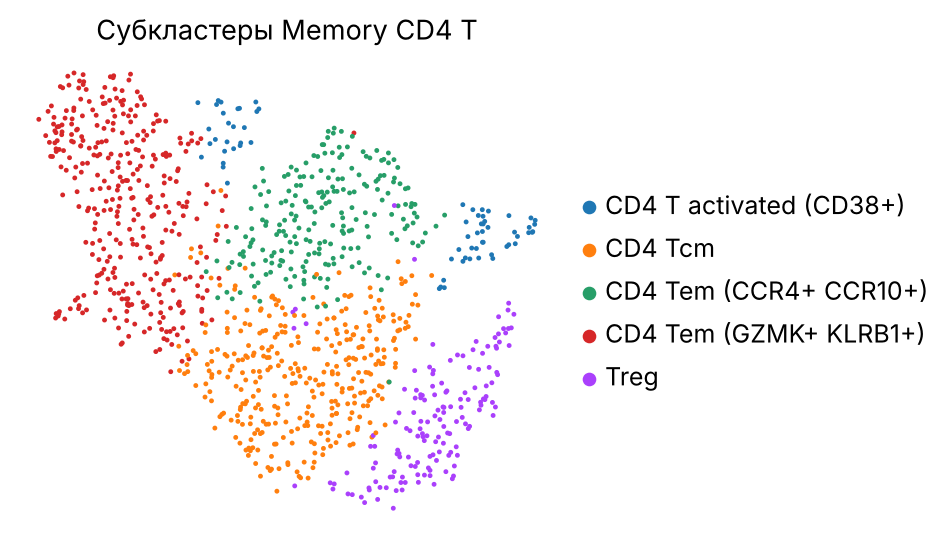

,n_cells
cell_type_refined,
CD14+ Monocyte,1590
Naive CD4 T,1258
NK CD56dim,716
Naive CD8 T,495
MAIT,391
CD4 Tem (GZMK+ KLRB1+),348
Effector memory CD8 T,348
CD4 Tcm,343
Naive B,307


In [30]:
sub_names = {
    "0": "CD4 Tem (GZMK+ KLRB1+)",
    "1": "CD4 Tcm",
    "2": "CD4 Tem (CCR4+ CCR10+)",
    "3": "CD4 T activated (CD38+)",
    "4": "Treg",
}
sub.obs["sub_cell_type"] = pd.Categorical(sub.obs["sub_leiden"].astype(str).map(sub_names))
sc.pl.umap(sub, color=["sub_cell_type"], size=25, title="Субкластеры Memory CD4 T")

# Переносим уточнённую аннотацию в общий объект
pbmc.obs["cell_type_refined"] = pbmc.obs["manual_cell_type"].astype(str)
pbmc.obs.loc[sub.obs_names, "cell_type_refined"] = sub.obs["sub_cell_type"].astype(str)
pbmc.obs["cell_type_refined"] = pd.Categorical(pbmc.obs["cell_type_refined"])
display(pbmc.obs["cell_type_refined"].value_counts().to_frame("n_cells"))

**Ответы на вопросы задания 6.**

- *Удалось ли разделить популяцию?* Да, на 5 интерпретируемых субпопуляций. Самая убедительная — **Treg** (152 клетки, 13 % памяти CD4, ~2 % всех PBMC): её подтверждают одновременно мРНК (`FOXP3`, `IKZF2`), белки (CD25^high CD127^low) и SingleR. Хорошо разделяются также центральная (CCR7⁺) и эффекторная (GZMK⁺/CCR4⁺) память.
- *Какие гены отличают субкластеры?* См. таблицу выше: `FOXP3/IKZF2/RTKN2` (Treg), `CCR7/SELL/TCF7` (Tcm), `GZMK/KLRB1/CCL5` (цитотоксически-подобная Tem), `CCR4/CCR10/S100A4` (CCR10⁺ Tem), `CD38/HAVCR2` (активированные).
- *Почему это не было видно в общей кластеризации?* Гены вроде `FOXP3` и `IL2RA` формально входили в глобальные HVG, но в общей PCA доминируют различия между линиями (PC1 — миелоидные vs лимфоциты, 26 % дисперсии), а различия внутри памяти CD4 определяются несколькими редко детектируемыми генами (`FOXP3` виден лишь у ~27 % Treg из-за dropout) и попадают в младшие компоненты. В результате в общем kNN-графе Treg остаются соседями других CD4 памяти, и модулярность при resolution 1.0 выгоднее держать их внутри одного сообщества. После выделения подмножества HVG и PCA пересчитываются **только по вариабельности внутри CD4 памяти**, и эти различия становятся главными осями.
- Ограничение: субкластеры 0–2 скорее отражают континуум состояний памяти, чем строго дискретные типы, поэтому их названия указывают на фенотип, а не на «линию» Th.

## Задание 7. Генные программы

| Программа | Гены | Источник |
|---|---|---|
| Цитотоксичность | `NKG7`, `PRF1`, `GZMA`, `GZMB`, `GZMH`, `GNLY`, `CST7`, `CTSW` | гены цитотоксических гранул (перфорин, гранзимы, гранулизин); близкий набор — сигнатура «cytotoxicity» в Guo et al., *Nat. Med.* 2018 |
| Ответ на интерферон I типа | `ISG15`, `IFI6`, `IFI44L`, `IFIT1`, `IFIT3`, `MX1`, `OAS1`, `RSAD2`, `STAT1`, `IRF7` | ядро набора MSigDB `HALLMARK_INTERFERON_ALPHA_RESPONSE` |
| Пролиферация | `MKI67`, `TOP2A`, `PCLAF`, `TYMS`, `MCM2`, `PCNA`, `BIRC5`, `CENPF`, `UBE2C`, `STMN1` | маркеры S- и G2/M-фаз из Tirosh et al., *Science* 2016 (те же списки использует `sc.tl.score_genes_cell_cycle`) |

Как и в семинаре, `score_genes` = средняя экспрессия набора минус средняя экспрессия контрольных генов того же уровня экспрессии.

cytotoxic_score: 8/8 генов найдено
ifn_score: 10/10 генов найдено


prolif_score: 10/10 генов найдено


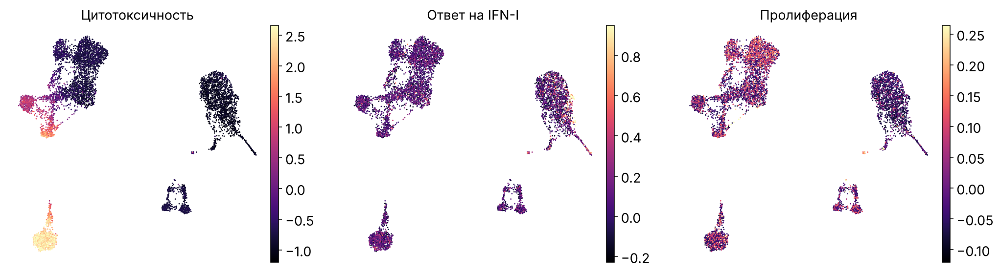

In [31]:
PROGRAMS = {
    "cytotoxic_score": ["NKG7", "PRF1", "GZMA", "GZMB", "GZMH", "GNLY", "CST7", "CTSW"],
    "ifn_score":       ["ISG15", "IFI6", "IFI44L", "IFIT1", "IFIT3", "MX1", "OAS1", "RSAD2", "STAT1", "IRF7"],
    "prolif_score":    ["MKI67", "TOP2A", "PCLAF", "TYMS", "MCM2", "PCNA", "BIRC5", "CENPF", "UBE2C", "STMN1"],
}
for name, genes in PROGRAMS.items():
    present = [g for g in genes if g in pbmc.var_names]
    print(f"{name}: {len(present)}/{len(genes)} генов найдено")
    sc.tl.score_genes(pbmc, gene_list=present, score_name=name, use_raw=False, random_state=42)

sc.pl.umap(pbmc, color=list(PROGRAMS), ncols=3, size=8, cmap="magma", vmax="p99.5",
           title=["Цитотоксичность", "Ответ на IFN-I", "Пролиферация"])

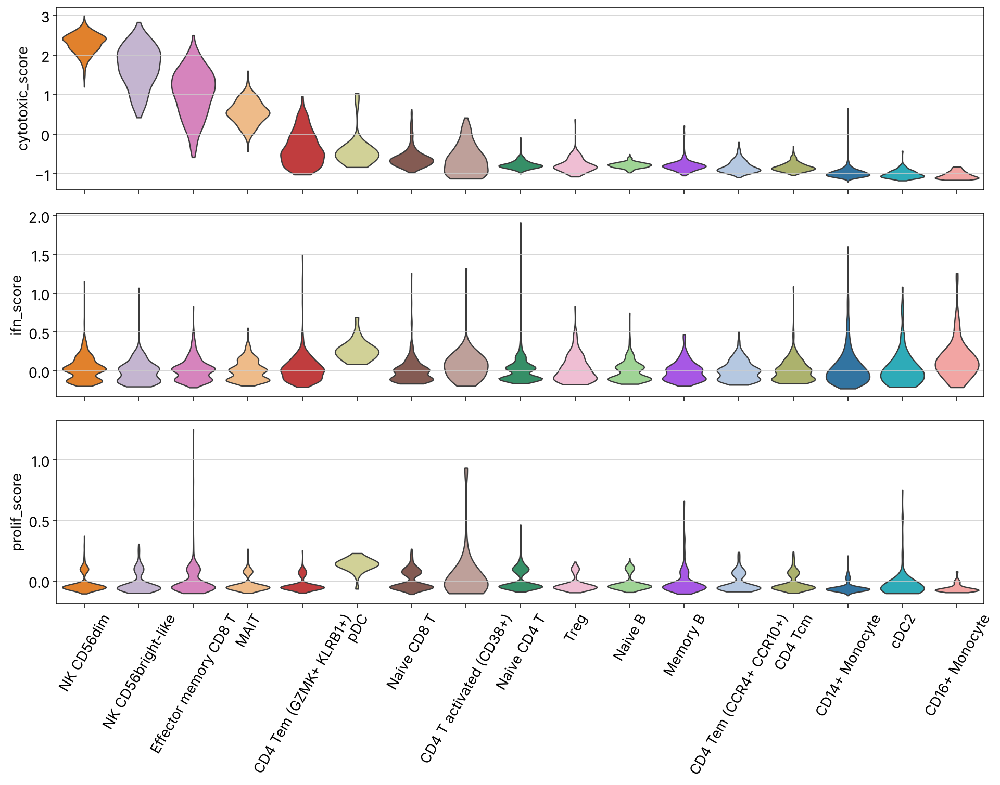

,cytotoxic_score,ifn_score,prolif_score
cell_type_refined,,,
NK CD56dim,2.30,0.03,-0.02
NK CD56bright-like,1.71,-0.01,-0.02
Effector memory CD8 T,1.03,0.02,-0.00
MAIT,0.55,0.01,-0.02
CD4 Tem (GZMK+ KLRB1+),-0.36,0.03,-0.03
pDC,-0.42,0.27,0.13
Naive CD8 T,-0.60,0.00,0.01
CD4 T activated (CD38+),-0.65,0.07,0.04
Naive CD4 T,-0.77,0.01,0.01


In [32]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
order = (pbmc.obs.groupby("cell_type_refined", observed=True)["cytotoxic_score"]
         .mean().sort_values(ascending=False).index.tolist())
for ax, name in zip(axes, PROGRAMS):
    sc.pl.violin(pbmc, name, groupby="cell_type_refined", order=order, rotation=60,
                 stripplot=False, ax=ax, show=False)
    ax.set_xlabel("")
for ax in axes[:-1]:
    ax.set_xticklabels([])
plt.tight_layout()
plt.show()

prog_summary = (pbmc.obs.groupby("cell_type_refined", observed=True)[list(PROGRAMS)]
                .mean().sort_values("cytotoxic_score", ascending=False))
display(prog_summary.style.background_gradient(cmap="Reds", axis=0).format("{:.2f}"))

In [33]:
# Сколько клеток с явно высокими scores и где они находятся
for name, thr in [("prolif_score", 0.3), ("ifn_score", 0.5)]:
    hi = pbmc.obs[name] > thr
    print(f"{name} > {thr}: {hi.sum()} клеток ({hi.mean():.1%}); по типам:")
    display(pbmc.obs.loc[hi, "cell_type_refined"].value_counts().head(8).to_frame("n_cells").T)

prolif_score > 0.3: 26 клеток (0.4%); по типам:


cell_type_refined,Naive CD4 T,Memory B,CD4 T activated (CD38+),Effector memory CD8 T,cDC2,NK CD56dim,NK CD56bright-like,CD14+ Monocyte
n_cells,6,5,4,4,4,2,1,0


ifn_score > 0.5: 139 клеток (2.0%); по типам:


cell_type_refined,CD14+ Monocyte,CD16+ Monocyte,Naive CD8 T,CD4 Tem (GZMK+ KLRB1+),cDC2,CD4 Tcm,NK CD56dim,Naive CD4 T
n_cells,95,8,7,5,4,3,3,3


**Где выражена каждая программа.**

- **Цитотоксичность** образует чёткий градиент: NK CD56dim (2.30) > NK CD56bright-like (1.71) > Effector memory CD8 T (1.03) > MAIT (0.55) > CD4 Tem GZMK⁺ (−0.36) > все остальные (≈ −0.6…−1.0).
- **Ответ на IFN I типа** у здорового донора слабый. Высокий score (> 0.5) — у 139 клеток (2 %), из них 95 — CD14⁺ моноциты: это небольшое ISG-high состояние моноцитов (`ISG15`, `IFI6`, `MX1`), которое не образует отдельного кластера. Среднее максимально у pDC (0.27), но там его почти целиком даёт `IRF7` — транскрипционный фактор, конститутивно высокий в pDC, а не индуцированные ISG (`ISG15`, `IFI6` у pDC около нуля).
- **Пролиферация** почти отсутствует: лишь 26 клеток (0,4 %) имеют score > 0.3, и они разбросаны по разным типам. Повышенное среднее у pDC (0.13) объясняется одним геном `STMN1`, который pDC экспрессируют независимо от клеточного цикла. Это ожидаемо: в периферической крови здорового человека делящихся клеток единицы процентов.

**Как генные программы помогают уточнить аннотацию — примеры из этих данных.**

1. Цитотоксический score отделяет NK CD56dim от CD56bright-подобных NK и **эффекторные** CD8 от **наивных** CD8 (1.03 vs −0.60), подтверждая разделение, сделанное по отдельным маркерам.
2. Внутри Memory CD4 T он выделяет цитотоксически-подобную эффекторную память (субкластер 0: −0.36 против −0.8 у остальных CD4), т.е. подтверждает, что субкластеризация нашла реальное функциональное различие.
3. IFN-score показывает, что в моноцитах есть подмножество в состоянии интерферонового ответа — это **состояние**, а не новый тип, поэтому оно не получает отдельной метки.
4. Пролиферативный score позволил не назвать субкластер 3 «cycling»: несмотря на `PCLAF`/`BIRC5` среди маркеров, по программе в целом он лишь слегка выше фона, поэтому назван «activated».

Примеры с pDC (IRF7, STMN1) показывают главное ограничение: score — это относительная экспрессия набора генов, и один ген с высоким базовым уровнем в конкретном типе может создать высокий score без реальной биологической программы. Высокий score — повод проверить отдельные гены, а не доказательство функции.

## Задание 8. Итоговые результаты

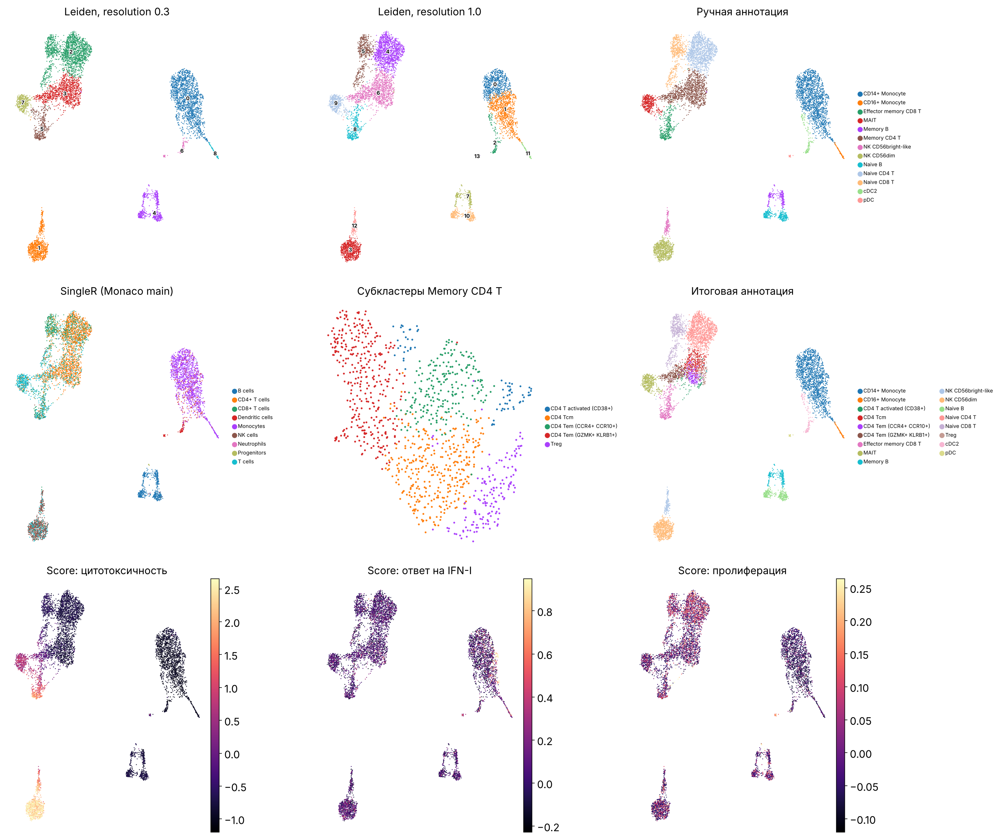

In [34]:
panels = [
    (pbmc, "leiden_0.3", "Leiden, resolution 0.3"),
    (pbmc, "leiden_1.0", "Leiden, resolution 1.0"),
    (pbmc, "manual_cell_type", "Ручная аннотация"),
    (pbmc, "singler_main", "SingleR (Monaco main)"),
    (sub, "sub_cell_type", "Субкластеры Memory CD4 T"),
    (pbmc, "cell_type_refined", "Итоговая аннотация"),
    (pbmc, "cytotoxic_score", "Score: цитотоксичность"),
    (pbmc, "ifn_score", "Score: ответ на IFN-I"),
    (pbmc, "prolif_score", "Score: пролиферация"),
]
fig, axes = plt.subplots(3, 3, figsize=(19, 16))
for ax, (obj, key, title) in zip(axes.ravel(), panels):
    is_cat = obj.obs[key].dtype.name == "category"
    kwargs = dict(legend_loc="on data" if key.startswith("leiden") else "right margin",
                  legend_fontsize=7, legend_fontoutline=2) if is_cat else dict(cmap="magma", vmax="p99.5")
    sc.pl.umap(obj, color=key, ax=ax, show=False, title=title,
               size=6 if obj is pbmc else 25, **kwargs)
plt.tight_layout()
plt.show()

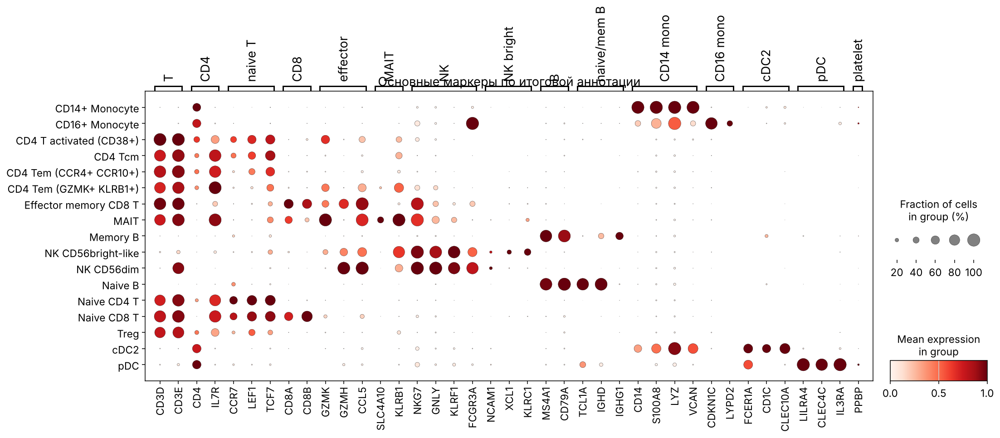

In [35]:
sc.pl.dotplot(pbmc, markers_hw, groupby="cell_type_refined", standard_scale="var",
              use_raw=False, figsize=(17, 6), title="Основные маркеры по итоговой аннотации")

In [36]:
out_full = HW_DIR / "pbmc10k_annotated.h5ad"
out_sub = HW_DIR / "pbmc10k_memoryCD4_subclustered.h5ad"
out_tab = HW_DIR / "pbmc10k_cluster_annotation.csv"

pbmc.write_h5ad(out_full, compression="gzip")
sub.write_h5ad(out_sub, compression="gzip")
(cluster_vote.reset_index().rename(columns={CLUSTER_KEY: "cluster"})
 .to_csv(out_tab, index=False))
for p in [out_full, out_sub, out_tab]:
    print(p, f"({p.stat().st_size / 1024**2:.1f} МБ)")

data/hw/pbmc10k_annotated.h5ad (63.5 МБ)
data/hw/pbmc10k_memoryCD4_subclustered.h5ad (24.7 МБ)
data/hw/pbmc10k_cluster_annotation.csv (0.0 МБ)


### Заключение

1. **Основные популяции.** В 6808 PBMC после QC найдены 13 типов клеток: CD14⁺ и CD16⁺ моноциты, cDC2 и pDC; наивные CD4 и CD8 T, Memory CD4 T, эффекторные CD8 T, MAIT; NK CD56dim и NK CD56bright-подобные; наивные и memory B. Субкластеризация памяти CD4 добавила Treg, Tcm, две группы Tem и активированные CD4 — всего 17 итоговых меток.
2. **Маркеры.** Ключевые: `CD14/S100A8/VCAN` и `CDKN1C/LYPD2/FCGR3A` (моноциты), `FCER1A/CD1C` (cDC2), `LILRA4/CLEC4C` (pDC), `CCR7/LEF1/TCF7` (наивные T), `CD8A/CD8B`, `GZMH/CCL5` (эффекторные CD8), `SLC4A10/KLRB1` (MAIT), `GNLY/KLRF1/FGFBP2` и `KLRC1/XCL1` (NK), `TCL1A/IGHD` и `IGHG1/TNFRSF13B` (наивные и memory B), `FOXP3/IKZF2` (Treg). Белки CITE-seq (CD3, CD4, CD8a, CD16, CD19, CD45RA/RO, CD25/CD127) подтвердили все крупные метки.
3. **Согласие ручной и автоматической аннотации.** 74 % клеток на уровне линий; на уровне кластеров большинство меток совпадает. Главные расхождения — наивные CD4 → «CD8», NK и эффекторные CD8 → «T cells (γδ/MAIT)», часть моноцитов → «DC»; в первых двух случаях белки показали, что ошибается SingleR. Причины — dropout ключевых генов (`CD4`), общие цитотоксические программы и bulk-референс.
4. **Субкластеризация.** Кластер Memory CD4 T распался на Treg (FOXP3⁺, CD25^high CD127^low), центральную память (CCR7⁺ SELL⁺), GZMK⁺ KLRB1⁺ эффекторную память, CCR4⁺ CCR10⁺ эффекторную память и небольшую группу активированных CD38⁺ PD-1⁺ клеток. Treg в общей кластеризации были не видны.
5. **Что дали генные программы.** Цитотоксичность выстроила градиент NK > эффекторные CD8 > MAIT > CD4 Tem и подтвердила функциональное различие внутри памяти CD4. IFN-score выявил небольшое ISG-high состояние моноцитов (~6 % моноцитов). Пролиферация в здоровой крови практически отсутствует. Случаи pDC показали, что высокий score нужно проверять по отдельным генам.

*Примечание о воспроизводимости:* все шаги зафиксированы `random_state=42`. На другой версии scanpy/igraph номера Leiden-кластеров могут сдвинуться — тогда словари `manual_hw` и `sub_names` нужно сверить с таблицами маркеров.